# HyperCP structures: from L1AQC to a Full-FRM calibrated DALEC spectrum

**Goal of this notebook.** Understand — by *looking at your own data* — what is inside

1. the **L1AQC HDF5 files** that HyperCP hands to the L1B stage,
2. the **factory calibration file** (`*.cal`) of the DALEC,
3. the **FidRadDB characterisation files** (`CP_DAL_*_RADCAL / STRAY / THERMAL / ANGULAR / POLAR`),

and then to see, step by step, what the **FRM full-sensor calibration** does to a raw DALEC record, how each matrix/vector is applied, and where the **6S atmospheric model** comes in.

**How it is organised**

| § | Topic | What you will see |
|---|---|---|
| 0 | Setup | repository, imports |
| 1 | Last GUI session | the input/output directories and configuration HyperCP used last (re-used here, read-only) |
| 2 | The HDF5 container | groups / datasets / structured arrays — a tree of your L1AQC file |
| 3 | DALEC L1AQC content | raw counts, dark counts, integration times, detector temperature, geometry |
| 4 | Factory calibration | the equation, the coefficients, and the factory-calibrated spectra |
| 5 | FidRadDB files | file anatomy and one visual section per characterisation type |
| 6 | The 6S model | what it is, what it gives HyperCP, how it enters the cosine correction |
| 7 | The FRM chain, step by step | each correction applied in order, and its size per wavelength |
| 8 | FRM vs factory | how different are the two calibrations over your whole file? |
| 9 | Cross-check | compare this notebook with `ProcessL1bDALEC.processL1b_FRM` |
| 10 | Glossary & open questions | assumptions worth verifying |

**Conventions.** `ES` = Ed (downwelling irradiance), `LI` = Lsky (sky radiance), `LT` = Lu (upwelling radiance) — HyperCP's names for the three DALEC channels. Spectral irradiance is in µW cm⁻² nm⁻¹ and radiance in µW cm⁻² nm⁻¹ sr⁻¹ (HyperCP's L1B units; the factory file itself is in W m⁻² nm⁻¹, hence the factor 100).

**Safety.** This notebook only *reads* HyperCP configuration (`MainConfig.loadConfig` / `ConfigFile.loadConfig`). It never calls any `saveConfig`, so it cannot change what the GUI will use next time. Anything that you may want to edit is in an UPPER_CASE variable at the top of a cell.

> **A note on naming.** You wrote "S6 model". The model used by HyperCP is **6S** — *Second Simulation of the Satellite Signal in the Solar Spectrum* (Vermote et al., 1997) — a radiative-transfer code. Section 6 explains it.

## 0. Setup

In [1]:
import os, sys, re, json, glob, copy, datetime as dt, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, SymLogNorm
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=RuntimeWarning)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'axes.titlesize': 10,
                     'axes.labelsize': 9, 'legend.fontsize': 8, 'figure.autolayout': True})
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 170); pd.set_option('display.max_colwidth', 90)

# The notebook lives in <repo>/Exploration/ ; find the repository root from wherever Jupyter was started.
HERE = Path.cwd().resolve()
REPO = next((p for p in [HERE, *HERE.parents] if (p / 'Source' / 'ConfigFile.py').exists()), None)
if REPO is None:
    raise RuntimeError('Start Jupyter from inside the HyperCP repository (e.g. from the Exploration/ folder).')
sys.path.insert(0, str(REPO))

from Source.MainConfig import MainConfig
from Source.ConfigFile import ConfigFile
from Source.HDFRoot import HDFRoot
from Source.HDFGroup import HDFGroup
from Source.ProcessL1aDALEC import ProcessL1aDALEC
import Source.utils.filing as filing

def rp(p):
    """Resolve a (possibly relative, './Data'-style) HyperCP path against the repository root."""
    p = Path(p)
    return p if p.is_absolute() else (REPO / p).resolve()

print('Repository root:', REPO)

INFO:root:Running from source


Repository root: /Users/lisacalus/Documents/Code/HyperCP


## 1. Re-using the last GUI session

When you press *OK* in the HyperCP window, two JSON files in `Config/` remember your choices:

* **`Config/main.config`** (class `MainConfig`) — the *window* state: the last **configuration name** (`cfgFile`), the **input** and **output** directories (`inDir`, `outDir`) and the ancillary file.
* **`Config/<name>.cfg`** (class `ConfigFile`) — one file per *configuration*: sensor type, calibration mode `fL1bCal`, QC thresholds, default AOD, … plus a `Config/<name>_Calibration/` folder with the factory calibration file(s).

`MainConfig.settings` and `ConfigFile.settings` are the very same dictionaries that the processing code reads, so by loading them here, any HyperCP function you call from this notebook behaves exactly as it would in the GUI.

In [2]:
# --- 1a. window state ------------------------------------------------------------------------------
MainConfig.loadConfig(MainConfig.fileName, 'exploration')      # read-only (we never call saveConfig)
MAIN = dict(MainConfig.settings)
CFG_NAME = MAIN['cfgFile']
IN_DIR, OUT_DIR = rp(MAIN['inDir']), rp(MAIN['outDir'])
ANC_FILE = MAIN.get('ancFile') or ''

# --- 1b. the configuration that was active -----------------------------------------------------------
ConfigFile.loadConfig(CFG_NAME)
S = ConfigFile.settings
CAL_MODES = {1: 'Factory', 2: 'FRM-Class', 3: 'FRM-Full (sensor-specific characterisation)'}

summary = pd.DataFrame([
    ('main.config',            REPO / 'Config' / MainConfig.fileName,      (REPO / 'Config' / MainConfig.fileName).is_file()),
    ('Last configuration',     CFG_NAME,                                   (REPO / 'Config' / CFG_NAME).is_file()),
    ('Input directory',        IN_DIR,                                     IN_DIR.is_dir()),
    ('Output directory',       OUT_DIR,                                    OUT_DIR.is_dir()),
    ('Ancillary file',         ANC_FILE or '(none)',                       os.path.isfile(ANC_FILE) if ANC_FILE else None),
    ('Calibration folder',     Path(ConfigFile.getCalibrationDirectory()), Path(ConfigFile.getCalibrationDirectory()).is_dir()),
    ('Sensor type',            S['SensorType'],                            None),
    ('L1B calibration mode',   f"fL1bCal = {S['fL1bCal']}  →  {CAL_MODES.get(S['fL1bCal'], '?')}", None),
], columns=['item', 'value', 'exists'])
display(summary)

KEYS = {
 'fL1bCal': 'L1B calibration: 1 Factory, 2 FRM-Class, 3 FRM-Full',
 'fL1bThermal': 'thermal-correction option (SeaBird/TriOS style flag)',
 'bL1aqcSunTracker': 'use SunTracker geometry (SZA, relative azimuth) from the instrument',
 'fL1aUTCOffset': 'UTC offset applied at L1A [h]',
 'bL1aCleanSZA': 'discard files with SZA above limit at L1A', 'fL1aCleanSZAMax': 'SZA limit [deg]',
 'bL1aqcDeglitch': 'deglitching at L1AQC (SeaBird only)',
 'bL1bGetAnc': 'download ancillary/model data (ECMWF) at L1B',
 'fL1bDefaultAOD': 'default AOD(550) used by 6S if no ancillary AOD', 'fL1bDefaultWindSpeed': 'default wind speed [m/s]',
 'fL1bDefaultSalt': 'default salinity', 'fL1bDefaultSST': 'default SST [°C]', 'fL1bDefaultAirT': 'default air temperature [°C]',
 'fL1bInterpInterval': 'L1B wavelength interpolation interval [nm]',
}
display(pd.DataFrame([(k, S.get(k, '(missing)'), v) for k, v in KEYS.items()], columns=['setting', 'value', 'meaning']))

# --- 1c. what HyperCP has already written in the output directory ------------------------------------
rows = []
for lvl in ['L1A', 'L1AQC', 'L1B', 'L1BQC', 'L2']:
    files = sorted(glob.glob(str(OUT_DIR / lvl / '**' / '*.hdf'), recursive=True))
    rows.append((lvl, len(files), Path(files[-1]).name if files else '-'))
display(pd.DataFrame(rows, columns=['level', '# hdf files', 'newest (by name)']))

,item,value,exists
0,main.config,/Users/lisacalus/Documents/Code/HyperCP/Config/main.config,True
1,Last configuration,SS_202506_DALEC11.cfg,True
2,Input directory,/Users/lisacalus/Documents/marsens/01_DATA/DALEC/testdata,True
3,Output directory,/Users/lisacalus/Documents/marsens/01_DATA/DALEC/testdata,True
4,Ancillary file,LW_SS_underway_20240527_20251121.txt,False
5,Calibration folder,/Users/lisacalus/Documents/Code/HyperCP/Config/SS_202506_DALEC11_Calibration,True
6,Sensor type,Dalec,None
7,L1B calibration mode,fL1bCal = 3 → FRM-Full (sensor-specific characterisation),None


,setting,value,meaning
0,fL1bCal,3.0,"L1B calibration: 1 Factory, 2 FRM-Class, 3 FRM-Full"
1,fL1bThermal,1.0,thermal-correction option (SeaBird/TriOS style flag)
2,bL1aqcSunTracker,1.0,"use SunTracker geometry (SZA, relative azimuth) from the instrument"
3,fL1aUTCOffset,0.0,UTC offset applied at L1A [h]
4,bL1aCleanSZA,1.0,discard files with SZA above limit at L1A
5,fL1aCleanSZAMax,70.0,SZA limit [deg]
6,bL1aqcDeglitch,0.0,deglitching at L1AQC (SeaBird only)
7,bL1bGetAnc,0.0,download ancillary/model data (ECMWF) at L1B
8,fL1bDefaultAOD,0.2,default AOD(550) used by 6S if no ancillary AOD
9,fL1bDefaultWindSpeed,5.0,default wind speed [m/s]


,level,# hdf files,newest (by name)
0,L1A,22,DALEC_11_2025-06-04_170000Z_L1A.hdf
1,L1AQC,2,DALEC_11_2025-06-04_160000Z_L1AQC.hdf
2,L1B,2,DALEC_11_2025-06-04_160000Z_L1B.hdf
3,L1BQC,0,-
4,L2,0,-


In [3]:
# --- 1d. choose the files that the rest of the notebook will explore -------------------------------------
def newest(pattern):
    files = sorted(glob.glob(pattern, recursive=True), key=os.path.getmtime)
    return Path(files[-1]) if files else None

L1AQC_FILE = None      # <-- set e.g. Path('/path/to/xxx_L1AQC.hdf') to pick a specific file; None = newest in OUT_DIR/L1AQC
L1AQC_FILE = Path(L1AQC_FILE) if L1AQC_FILE else newest(str(OUT_DIR / 'L1AQC' / '**' / '*_L1AQC.hdf'))

L1B_FILE = None
if L1AQC_FILE is not None:
    stem = L1AQC_FILE.name.rsplit('_L1AQC', 1)[0]
    L1B_FILE = newest(str(OUT_DIR / 'L1B' / '**' / f'{stem}_L1B.hdf'))

CAL_DIR = Path(ConfigFile.getCalibrationDirectory())
enabled = [k for k, v in S.get('CalibrationFiles', {}).items() if (v.get('enabled') if isinstance(v, dict) else v)]
cal_candidates = [CAL_DIR / k for k in enabled if k.lower().endswith('.cal')] or sorted(CAL_DIR.glob('*.cal'))
CAL_FILE = next((c for c in cal_candidates if c.is_file()), None)

FID_DIR = next((p for p in (REPO / 'Data' / 'FidRadDB').glob('*') if p.is_dir() and p.name.lower() == 'dalec'), None)

IS_DALEC = str(S['SensorType']).lower() == 'dalec'
HAVE_L1AQC, HAVE_CAL, HAVE_FID = L1AQC_FILE is not None, CAL_FILE is not None, FID_DIR is not None and any(FID_DIR.glob('CP_DAL_*'))
display(pd.DataFrame([('L1AQC file', L1AQC_FILE), ('L1B file (optional, for SIXS_MODEL)', L1B_FILE), ('Factory .cal', CAL_FILE),
                      ('FidRadDB/Dalec', FID_DIR), ('Sensor is DALEC', IS_DALEC)], columns=['what', 'path / value']))
if not IS_DALEC:
    print('NOTE: the last configuration is not a DALEC one. The DALEC-specific sections (3 onwards) will be skipped.')
HAVE_L1AQC &= IS_DALEC; HAVE_CAL &= IS_DALEC; HAVE_FID &= IS_DALEC

,what,path / value
0,L1AQC file,/Users/lisacalus/Documents/marsens/01_DATA/DALEC/testdata/L1AQC/DALEC_11_2025-06-04_16...
1,"L1B file (optional, for SIXS_MODEL)",/Users/lisacalus/Documents/marsens/01_DATA/DALEC/testdata/L1B/DALEC_11_2025-06-04_1600...
2,Factory .cal,/Users/lisacalus/Documents/Code/HyperCP/Config/SS_202506_DALEC11_Calibration/DALEC_001...
3,FidRadDB/Dalec,/Users/lisacalus/Documents/Code/HyperCP/Data/FidRadDB/Dalec
4,Sensor is DALEC,True


## 2. The HDF5 container model

HyperCP files all have the same three-level shape, implemented by three small classes:

```
HDFRoot ─ attributes {…}                      ← file-level metadata (instrument serials, processing level, …)
 ├─ HDFGroup  'ES'  ─ attributes {…}          ← one per sensor / purpose (ES, LI, LT, CAL_COEF, ANCILLARY_METADATA, …)
 │    ├─ HDFDataset 'ES'        .data  = numpy structured array   (n_records × n_pixels, one *field* per pixel)
 │    ├─ HDFDataset 'DARK_CNT'  .data  = structured array with a single field (n_records)
 │    └─ …
 └─ HDFGroup  'LI' …
```

The unusual point is that a spectral dataset is a **structured (record) array whose field names are the wavelengths as text**
(`'303.776'`, `'307.099'`, …). To get a plain matrix you convert it: `np.array(ds.data.tolist(), float)`, and the wavelengths are `[float(n) for n in ds.data.dtype.names]`.
Scalar time series (dark counts, integration time, temperature, SZA …) are structured arrays with **one** field, whose name is a label (`'ES'`, `'NONE'`, `'REL_AZ'`).

Every group that holds time series also carries `DATETAG` (year + day-of-year, `YYYYDDD`) and `TIMETAG2` (`HHMMSSmmm`); `DATETIME` is rebuilt from them in memory but **is not stored** (HDF5 has no datetime type).

In [4]:
def first_field(ds):
    """Values of a one-field dataset as a float vector."""
    return np.asarray(ds.data[ds.data.dtype.names[0]], float)

def spectra(gp, name):
    """(n_records × n_pixels matrix, wavelength vector) of a spectral dataset."""
    d = gp.getDataset(name).data
    return np.array(d.tolist(), float), np.array([float(n) for n in d.dtype.names])

def group_datetimes(gp):
    """Rebuild timestamps from DATETAG (YYYYDDD) and TIMETAG2 (HHMMSSmmm), as HyperCP's Controller does."""
    d, t = first_field(gp.getDataset('DATETAG')), first_field(gp.getDataset('TIMETAG2'))
    return pd.DatetimeIndex([dt.datetime.strptime(f'{int(a)}{int(b):09d}', '%Y%j%H%M%S%f') for a, b in zip(d, t)])

def find_group(root, *ids):
    for i in ids:
        g = root.getGroup(i)
        if g is not None:
            return g
    return None

def hdf_tree(root, max_attr=6):
    """Print an indented tree of an HDFRoot: groups, datasets (shape, first/last field) and a few attributes."""
    print(f'/  ({len(root.attributes)} attributes)')
    for gp in root.groups:
        print(f'├── {gp.id}/   [{len(gp.datasets)} datasets, {len(gp.attributes)} attributes]')
        for k, v in list(gp.attributes.items())[:max_attr]:
            print(f'│     @{k} = {str(v)[:60]}')
        for name, ds in gp.datasets.items():
            d = ds.data
            if d is None or d.dtype.names is None:
                print(f'│   ├── {name}  (empty)'); continue
            f = d.dtype.names
            fields = f[0] if len(f) == 1 else f'{f[0]} … {f[-1]}'
            print(f'│   ├── {name:<16} {len(d):>5} rec × {len(f):>4} field(s)   [{fields}]')

if HAVE_L1AQC:
    ROOT = HDFRoot.readHDF5(str(L1AQC_FILE))
    print('File:', L1AQC_FILE.name, '\n')
    hdf_tree(ROOT)

File: DALEC_11_2025-06-04_160000Z_L1AQC.hdf 

/  (56 attributes)
├── ANCILLARY_METADATA/   [7 datasets, 6 attributes]
│     @FrameType = Not Required
│     @LATITUDE_UNITS = degrees
│     @LONGITUDE_UNITS = degrees
│     @SALINITY_UNITS = psu
│     @STATION_UNITS = none
│     @WINDSPEED_UNITS = m/s
│   ├── DATETAG             63 rec ×    1 field(s)   [NONE]
│   ├── LATITUDE            63 rec ×    1 field(s)   [NONE]
│   ├── LONGITUDE           63 rec ×    1 field(s)   [NONE]
│   ├── SALINITY            63 rec ×    1 field(s)   [NONE]
│   ├── STATION             63 rec ×    1 field(s)   [NONE]
│   ├── TIMETAG2            63 rec ×    1 field(s)   [NONE]
│   ├── WINDSPEED           63 rec ×    1 field(s)   [NONE]
├── CAL_COEF/   [3 datasets, 11 attributes]
│     @CalFileName = DALEC_0011_2025_02_04_V4.cal
│     @Delta_T_Ed = 4.120356
│     @Delta_T_Lsky = 4.177609
│     @Delta_T_Lu = 4.116045
│     @Tref = 24.0
│     @d0 = 1.003855
│   ├── Cal_ES             190 rec ×    2 field(s)   [a0 

In [30]:
gps = ROOT.groups

for gp in gps:
    for name, ds in gp.datasets.items():
        print(name, ds.data)

DATETAG [(2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,)
 (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,)
 (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,)
 (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,)
 (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,)
 (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,)
 (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,)
 (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,)
 (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,)
 (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,) (2025155.,)
 (2025155.,) (2025155.,) (2025155.,)]
LATITUDE [(55.81669923,) (55.81694258,) (55.81721277,) (55.81748063,)
 (55.81776063,) (55.81801085,) (55.81826767,) (55.81852075,)
 (55.81878123,) (55.81905975,) (55.81931355,) (55.81959295,)
 (55.81986487,) (55.82011113,) (

In [31]:
# File-level attributes (instrument identity comes from the factory .cal header, copied here at L1A)
if HAVE_L1AQC:
    display(pd.Series({k: (str(v)[:100]) for k, v in ROOT.attributes.items()}, name='root attribute').to_frame())

,root attribute
AUTOGEARPOSCAL,ON
AUTOINTTIME,ON
AUTOINTTIME_SCL,"{0.20,0.20,0.20}"
AUTOSTART,ON
AVAILABLE_MEMORY,109737.32 (MB)
CAL_FILE_NAMES,DALEC_0011_2025_02_04_V4.cal
CHANNEL_ORDER,"{Ed,Lu,Lsky}"
DALEC_serial_number,11
DARKPIXEND,"{255,255,255}"
DARKPIXSTART,"{240,240,240}"


## 3. What the DALEC L1AQC file contains

For each of the three channels the group holds

| dataset | meaning |
|---|---|
| `ES` / `LI` / `LT` | **raw 16-bit counts** per pixel and record (still *including* the dark offset) |
| `DARK_CNT` | the dark-current counts the DALEC measured for that record (one number per record, not per pixel) |
| `INTTIME` | integration time in ms — the DALEC chooses it **automatically** so the signal fills the detector, so it changes from record to record |
| `SPECTEMP` | detector temperature in °C (internal sensor) |
| `QFLAG` | instrument quality flag |
| `DATETAG`, `TIMETAG2` | time stamps |

Two things deserve attention because they determine how large each FRM correction is:

* **Signal level** (`V − DC`): non-linearity grows with the number of counts, so records near the top of the range are corrected more.
* **Temperature**: the thermal correction is proportional to `T − T_cal`, with `T_cal` taken from the THERMAL characterisation file.

In [32]:
L1 = {}
if HAVE_L1AQC:
    for s in ['ES', 'LI', 'LT']:
        g = find_group(ROOT, s, f'{s}_L1AQC')
        if g is None:
            print(f'group {s} not found'); continue
        X, wl = spectra(g, s)
        L1[s] = dict(g=g, raw=X, wl=wl, dc=first_field(g.getDataset('DARK_CNT')), t=first_field(g.getDataset('INTTIME')),
                     T=first_field(g.getDataset('SPECTEMP')), time=group_datetimes(g))
HAVE_L1 = len(L1) == 3

NAMES = {'ES': 'Ed  (ES)', 'LI': 'Lsky (LI)', 'LT': 'Lu  (LT)'}
COL = {'ES': 'tab:orange', 'LI': 'tab:blue', 'LT': 'tab:green'}
if HAVE_L1:
    inv = []
    for s, d in L1.items():
        v = d['raw'] - d['dc'][:, None]
        inv.append(dict(sensor=NAMES[s], records=len(d['t']), pixels=d['raw'].shape[1], wl_min=d['wl'].min(), wl_max=d['wl'].max(),
                        inttime_ms=f"{d['t'].min():.0f}–{d['t'].max():.0f}", T_C=f"{d['T'].min():.1f}–{d['T'].max():.1f}",
                        dark_counts=f"{d['dc'].min():.0f}–{d['dc'].max():.0f}", max_signal_counts=f'{v.max():.0f}',
                        start=d['time'][0].strftime('%Y-%m-%d %H:%M:%S'), end=d['time'][-1].strftime('%H:%M:%S')))
    display(pd.DataFrame(inv).set_index('sensor'))

,records,pixels,wl_min,wl_max,inttime_ms,T_C,dark_counts,max_signal_counts,start,end
sensor,,,,,,,,,,
Ed (ES),7728,190,340.169,967.992,33–70,19.0–19.4,799–826,42329,2025-06-04 15:59:59,16:59:59
Lsky (LI),7849,190,338.459,967.741,14–36,19.1–19.4,946–970,33766,2025-06-04 16:00:00,16:59:59
Lu (LT),6593,190,340.209,968.397,3–230,18.8–19.4,813–857,64722,2025-06-04 15:59:59,16:59:59


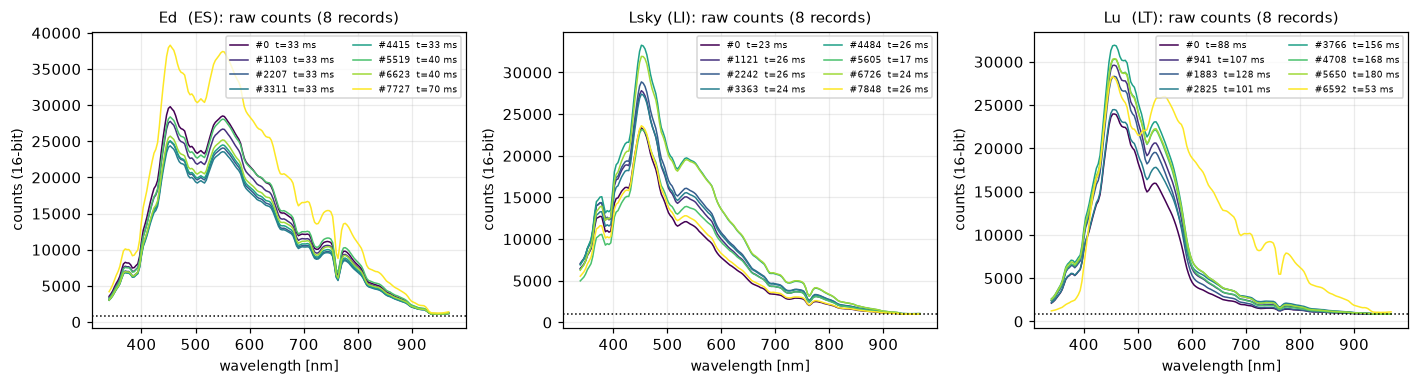

Dotted line = median dark counts. The raw spectrum sits on top of this offset; the first FRM step removes it.


In [33]:
if HAVE_L1:
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
    for a, s in zip(ax, ['ES', 'LI', 'LT']):
        d = L1[s]; idx = np.linspace(0, len(d['t']) - 1, 8).astype(int); cm = plt.cm.viridis(np.linspace(0, 1, len(idx)))
        for c, i in zip(cm, idx):
            a.plot(d['wl'], d['raw'][i], color=c, lw=1, label=f"#{i}  t={d['t'][i]:.0f} ms")
        a.axhline(np.median(d['dc']), color='k', ls=':', lw=1)
        a.set(title=f'{NAMES[s]}: raw counts (8 records)', xlabel='wavelength [nm]', ylabel='counts (16-bit)')
        a.legend(fontsize=6, ncol=2)
    plt.show()
    print('Dotted line = median dark counts. The raw spectrum sits on top of this offset; the first FRM step removes it.')

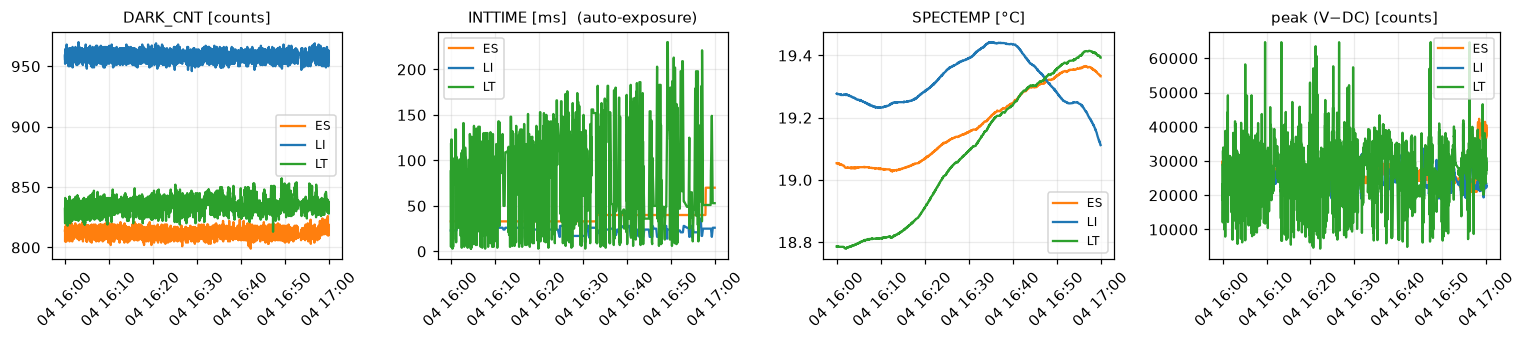

In [34]:
if HAVE_L1:
    fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
    for s in ['ES', 'LI', 'LT']:
        d = L1[s]
        ax[0].plot(d['time'], d['dc'], color=COL[s], label=s); ax[1].plot(d['time'], d['t'], color=COL[s], label=s)
        ax[2].plot(d['time'], d['T'], color=COL[s], label=s)
        ax[3].plot(d['time'], (d['raw'] - d['dc'][:, None]).max(axis=1), color=COL[s], label=s)
    for a, t in zip(ax, ['DARK_CNT [counts]', 'INTTIME [ms]  (auto-exposure)', 'SPECTEMP [°C]', 'peak (V−DC) [counts]']):
        a.set_title(t); a.tick_params(axis='x', labelrotation=45); a.legend()
    plt.show()

Ancillary group: SunTracker_DALEC → datasets: ['DATETAG', 'HUMIDITY', 'PITCH', 'POINTING', 'REL_AZ', 'ROLL', 'SOLAR_AZ', 'SZA', 'TILT', 'TIMETAG2', 'VOLTAGE']


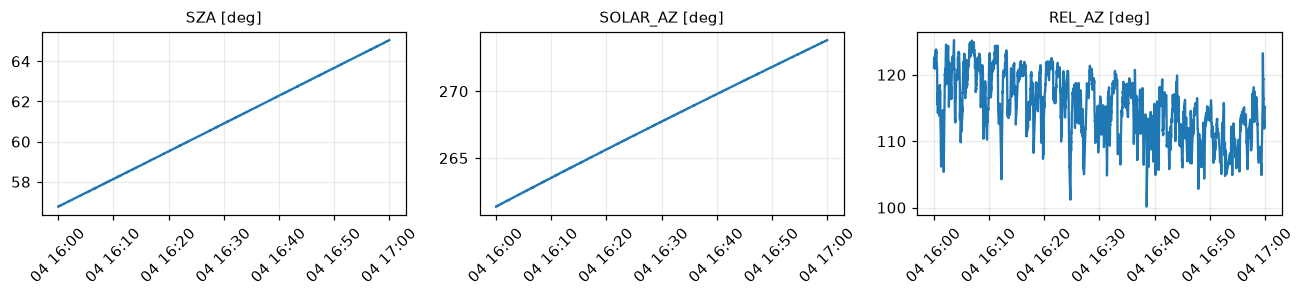

In [40]:
# Geometry / ancillary information stored next to the radiometry (used later by 6S and for QC)
ANC = find_group(ROOT, 'SunTracker_DALEC') if HAVE_L1AQC else None
if ANC is not None:
    print('Ancillary group:', ANC.id, '→ datasets:', list(ANC.datasets))
    try:
        anc_t = group_datetimes(ANC); fig, ax = plt.subplots(1, 3, figsize=(12, 2.8))
        for a, k in zip(ax, ['SZA', 'SOLAR_AZ', 'REL_AZ']):
            if k in ANC.datasets: a.plot(anc_t, first_field(ANC.getDataset(k))); a.set_title(k + ' [deg]'); a.tick_params(axis='x', labelrotation=45)
        plt.show()
    except Exception as err:
        print('Could not build a time axis for the ancillary group:', repr(err)); ANC = None
else:
    print('No ancillary group found (6S sections will fall back to defaults).')

In [41]:
ANC.datasets

OrderedDict([('DATETAG', <Source.HDFDataset.HDFDataset at 0x16c0ab070>),
             ('HUMIDITY', <Source.HDFDataset.HDFDataset at 0x16c0ab000>),
             ('PITCH', <Source.HDFDataset.HDFDataset at 0x16c0ab150>),
             ('POINTING', <Source.HDFDataset.HDFDataset at 0x16c0ab0e0>),
             ('REL_AZ', <Source.HDFDataset.HDFDataset at 0x16c0ab1c0>),
             ('ROLL', <Source.HDFDataset.HDFDataset at 0x16c0ab230>),
             ('SOLAR_AZ', <Source.HDFDataset.HDFDataset at 0x16c0ab2a0>),
             ('SZA', <Source.HDFDataset.HDFDataset at 0x16c0ab310>),
             ('TILT', <Source.HDFDataset.HDFDataset at 0x16c0ab380>),
             ('TIMETAG2', <Source.HDFDataset.HDFDataset at 0x16c0ab3f0>),
             ('VOLTAGE', <Source.HDFDataset.HDFDataset at 0x16c0ab460>)])

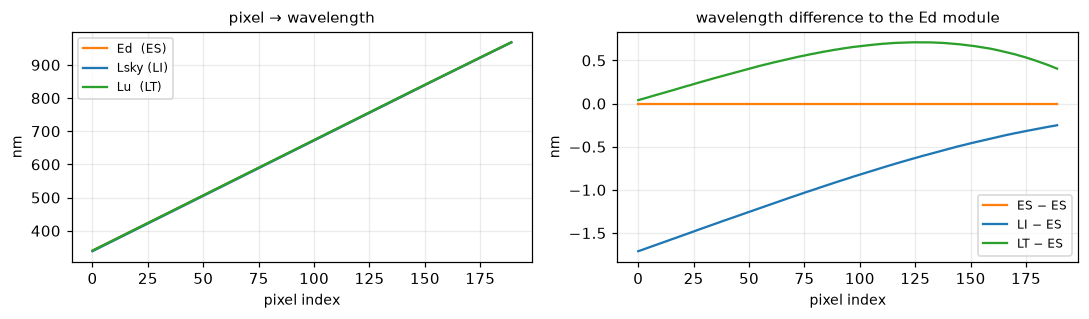

In [42]:
# The three spectrometer modules are different physical devices: same pixel *index* ≠ same wavelength.
if HAVE_L1:
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    for s in ['ES', 'LI', 'LT']:
        ax[0].plot(L1[s]['wl'], color=COL[s], label=NAMES[s])
        ax[1].plot(L1[s]['wl'] - L1['ES']['wl'], color=COL[s], label=f'{s} − ES')
    ax[0].set(title='pixel → wavelength', xlabel='pixel index', ylabel='nm'); ax[1].set(title='wavelength difference to the Ed module', xlabel='pixel index', ylabel='nm')
    ax[0].legend(); ax[1].legend(); plt.show()

## 4. The factory calibration (`*.cal`)

The `.cal` file written by the manufacturer holds, per channel, **one responsivity per pixel** and a handful of scalars. HyperCP's factory branch (`ProcessL1bDALEC.processSensor`) evaluates

$$
E(\lambda_i)\;=\;100\;\frac{a_{0,i}\;\;(V_i-DC)}{(t+\Delta T)\;K}\;\frac{1}{1+T_{c,i}\,(T-T_{ref})},\qquad K = d_1\,(V_i-DC)+d_0 ,
$$

with $V_i$ the raw counts of pixel $i$, $DC$ the dark counts, $t$ the integration time [ms], $\Delta T$ an **integration-time offset** (~4 ms: the effective exposure is longer than the nominal one), $a_0$ the responsivity coefficient (`b0` for Lu, `c0` for Lsky), $T_{c}$ the temperature coefficient and $T$ the detector temperature. The factor 100 converts W m⁻² nm⁻¹ → µW cm⁻² nm⁻¹.

What the factory model **does not** know about: *stray light* (light of one wavelength landing on pixels of other wavelengths), the *angular (cosine) response* of the irradiance collector, *polarisation sensitivity*, and a *measured* non-linearity per pixel. Those are exactly what the FidRadDB files add.

> ⚠️ **Naming gotcha.** The `.cal` header calls `d0` the "slope" and `d1` the "yint", but the numbers (`d0 ≈ 1.0046`, `d1 ≈ −5·10⁻⁷`) and the code (`K = d1·counts + d0`) show that `d0` is the constant term and `d1` the (tiny) slope with respect to counts. The same holds for `e0/e1` (Lu) and `f0/f1` (Lsky).

In [43]:
CH = {'ES': dict(a='a0', tc='Tempco_Ed',   lin=('d0', 'd1'), dT='Delta_T_Ed',   wl='Lambda_Ed',   mod='Ed_spectrometer_module'),
      'LT': dict(a='b0', tc='Tempco_Lu',   lin=('e0', 'e1'), dT='Delta_T_Lu',   wl='Lambda_Lu',   mod='Lu_spectrometer_module'),
      'LI': dict(a='c0', tc='Tempco_Lsky', lin=('f0', 'f1'), dT='Delta_T_Lsky', wl='Lambda_Lsky', mod='Lsky_spectrometer_module')}

if HAVE_CAL:
    CAL_META, CAL_COEFS, CAL_DATA = ProcessL1aDALEC.read_cal(str(CAL_FILE))
    META  = {r[1].strip().replace(' ', '_'): str(r[2]).strip() for r in CAL_META.itertuples()}
    COEF  = {r[1].strip().replace(' ', '_'): float(r[2]) for r in CAL_COEFS.itertuples()}
    print('Factory file:', CAL_FILE.name)
    display(pd.Series(META, name='instrument identity').to_frame())
    display(pd.Series(COEF, name='scalar coefficients').to_frame().T)
    print('\nPer-pixel table (first rows):'); display(CAL_DATA.head(4))

Factory file: DALEC_0011_2025_02_04_V4.cal


,instrument identity
DALEC_serial_number,11
Ed_spectrometer_module,159825
Lu_spectrometer_module,152238
Lsky_spectrometer_module,159829


,d0,d1,e0,e1,f0,f1,Delta_T_Ed,Delta_T_Lu,Delta_T_Lsky,Tref
scalar coefficients,1.003855,-4.390069e-07,1.004122,-4.641241e-07,1.003965,-4.470437e-07,4.120356,4.116045,4.177609,24.0



Per-pixel table (first rows):


,Pixel,Lambda_Ed,a0,Tempco_Ed,Lambda_Lu,b0,Tempco_Lu,Lambda_Lsky,c0,Tempco_Lsky
0,0,340.169,0.003707,-0.000341,340.209,0.000251,-0.000184,338.459,0.000227,-0.000643
1,1,343.483,0.003300,-0.000335,343.530,0.000237,-0.000174,341.781,0.000221,-0.000627
2,2,346.797,0.003195,-0.000330,346.851,0.000224,-0.000164,345.104,0.000210,-0.000612
3,3,350.111,0.002768,-0.000325,350.173,0.000211,-0.000155,348.428,0.000201,-0.000597


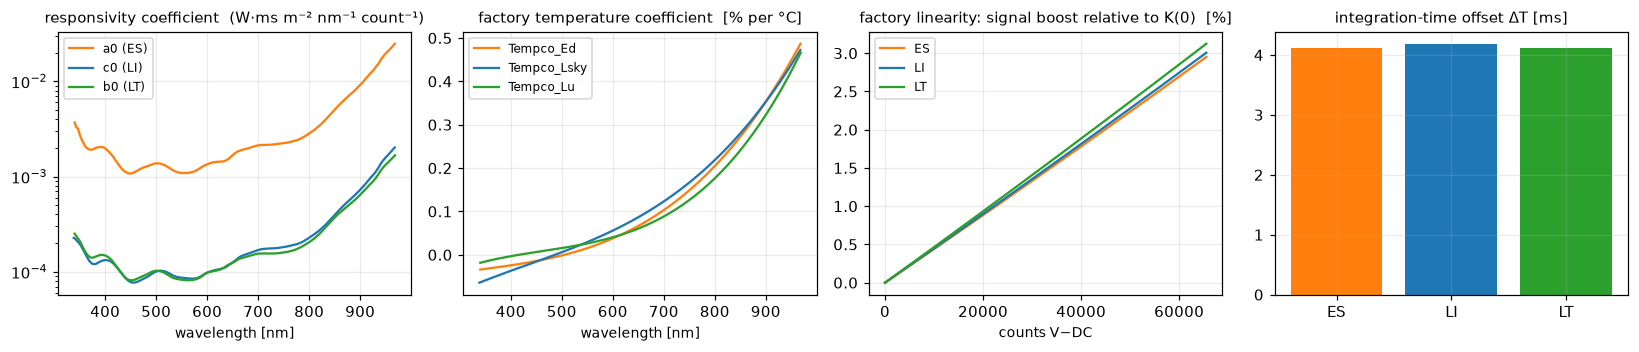

The linearity panel is the whole factory non-linearity model: one straight line in counts, identical for all pixels.


In [44]:
if HAVE_CAL:
    fig, ax = plt.subplots(1, 4, figsize=(15, 3.3))
    for s in ['ES', 'LI', 'LT']:
        wl = CAL_DATA[CH[s]['wl']]
        ax[0].semilogy(wl, CAL_DATA[CH[s]['a']], color=COL[s], label=f"{CH[s]['a']} ({s})")
        ax[1].plot(wl, CAL_DATA[CH[s]['tc']] * 100, color=COL[s], label=CH[s]['tc'])
    ax[0].set(title='responsivity coefficient  (W·ms m⁻² nm⁻¹ count⁻¹)', xlabel='wavelength [nm]'); ax[0].legend()
    ax[1].set(title='factory temperature coefficient  [% per °C]', xlabel='wavelength [nm]'); ax[1].legend()
    v = np.linspace(0, 65535, 400)
    for s in ['ES', 'LI', 'LT']:
        d0, d1 = COEF[CH[s]['lin'][0]], COEF[CH[s]['lin'][1]]
        ax[2].plot(v, (d0 / (d1 * v + d0) - 1) * 100, color=COL[s], label=s)       # relative boost of the signal by 1/K, normalised to K(0)
    ax[2].set(title='factory linearity: signal boost relative to K(0)  [%]', xlabel='counts V−DC'); ax[2].legend()
    for s in ['ES', 'LI', 'LT']:
        ax[3].bar(s, COEF[CH[s]['dT']], color=COL[s])
    ax[3].set(title='integration-time offset ΔT [ms]'); plt.show()
    print('The linearity panel is the whole factory non-linearity model: one straight line in counts, identical for all pixels.')

In [45]:
# --- the factory equation, implemented step by step (and checked against the CAL_COEF group stored in the L1AQC file) ---
def factory_cal(raw, dc, t, T, s):
    """Factory calibration of a (records × pixels) count matrix. Returns a dict with every intermediate stage."""
    c = CH[s]; d0, d1 = COEF[c['lin'][0]], COEF[c['lin'][1]]; dT, Tref = COEF[c['dT']], COEF['Tref']
    a, tc = CAL_DATA[c['a']].to_numpy(), CAL_DATA[c['tc']].to_numpy()
    st = {}
    st['V']      = raw
    st['V-DC']   = raw - dc[:, None]
    st['/K']     = st['V-DC'] / (d1 * st['V-DC'] + d0)                  # linearity
    st['rate']   = st['/K'] / (t + dT)[:, None]                         # counts per ms (effective exposure)
    st['E_20C']  = 100.0 * a[None, :] * st['rate']                      # responsivity -> µW cm-2 nm-1
    st['E']      = st['E_20C'] / (tc[None, :] * (T - Tref)[:, None] + 1)  # temperature
    return st

if HAVE_L1 and HAVE_CAL:
    FAC = {s: factory_cal(L1[s]['raw'], L1[s]['dc'], L1[s]['t'], L1[s]['T'], s)['E'] for s in L1}
    cc = find_group(ROOT, 'CAL_COEF')
    if cc is not None and 'Cal_ES' in cc.datasets:
        a_file = np.asarray(cc.getDataset('Cal_ES').data['a0'], float)
        print('a0 in the L1AQC file equals a0 in the .cal file:', np.allclose(a_file, CAL_DATA['a0']))
    print('wavelengths in the L1AQC ES group equal Lambda_Ed of the .cal file:', np.allclose(L1['ES']['wl'], CAL_DATA['Lambda_Ed'], atol=1e-3))

a0 in the L1AQC file equals a0 in the .cal file: True
wavelengths in the L1AQC ES group equal Lambda_Ed of the .cal file: True


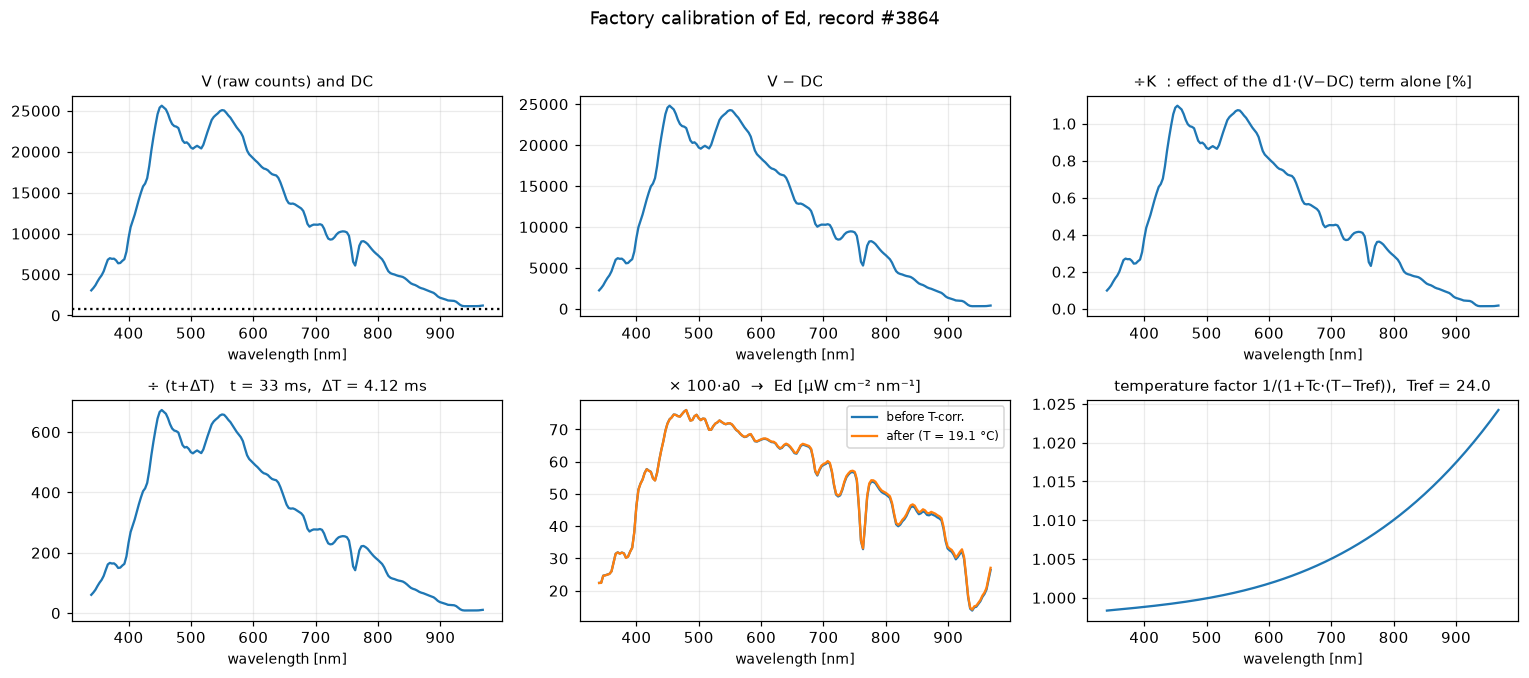

In [46]:
REC = None       # record index to inspect in the step-by-step plots (None = middle of the file)
if HAVE_L1 and HAVE_CAL:
    REC = len(L1['ES']['t']) // 2 if REC is None else REC
    fig, ax = plt.subplots(2, 3, figsize=(14, 6)); ax = ax.ravel()
    s = 'ES'; st = factory_cal(L1[s]['raw'][[REC]], L1[s]['dc'][[REC]], L1[s]['t'][[REC]], L1[s]['T'][[REC]], s); wl = L1[s]['wl']
    ax[0].plot(wl, st['V'][0]);      ax[0].axhline(L1[s]['dc'][REC], color='k', ls=':'); ax[0].set_title('V (raw counts) and DC')
    ax[1].plot(wl, st['V-DC'][0]);   ax[1].set_title('V − DC')
    ax[2].plot(wl, (COEF[CH[s]['lin'][0]] / (COEF[CH[s]['lin'][1]] * st['V-DC'][0] + COEF[CH[s]['lin'][0]]) - 1) * 100)
    ax[2].set_title('÷K  : effect of the d1·(V−DC) term alone [%]')
    ax[3].plot(wl, st['rate'][0]);   ax[3].set_title(f"÷ (t+ΔT)   t = {L1[s]['t'][REC]:.0f} ms,  ΔT = {COEF[CH[s]['dT']]:.2f} ms")
    ax[4].plot(wl, st['E_20C'][0], label='before T-corr.'); ax[4].plot(wl, st['E'][0], label=f"after (T = {L1[s]['T'][REC]:.1f} °C)")
    ax[4].set_title('× 100·a0  →  Ed [µW cm⁻² nm⁻¹]'); ax[4].legend()
    ax[5].plot(wl, st['E'][0] / st['E_20C'][0]); ax[5].set_title(f"temperature factor 1/(1+Tc·(T−Tref)),  Tref = {COEF['Tref']}")
    for a in ax: a.set_xlabel('wavelength [nm]')
    plt.suptitle(f'Factory calibration of Ed, record #{REC}', y=1.02); plt.show()

## 5. The FidRadDB characterisation files

FidRadDB is the database of **laboratory characterisations of individual instruments** produced in the FRM4SOC (*Fiducial Reference Measurements for Satellite Ocean Colour*) framework. Each file is a plain-text file in a common layout (`!FRM4SOC_CP` header, `[SECTIONS]` in square brackets, tab-separated tables). The file name tells you what it is:

```
CP_DAL_0011_152238_RADCAL_20260627092815.TXT
│  │   │    │      │      └── date/time of the characterisation (yyyymmddHHMMSS)
│  │   │    │      └───────── type:  RADCAL | STRAY | THERMAL | ANGULAR | POLAR
│  │   │    └──────────────── serial number of the *spectrometer module* (not of the DALEC!)
│  │   └───────────────────── DALEC serial number
│  └───────────────────────── instrument class (DAL = DALEC)
└──────────────────────────── CP = characterisation protocol
```

Each of the three modules (Ed, Lu, Lsky) is a separate device with its own set of files; the module → channel mapping is in the **factory `.cal` header** (`Ed spectrometer module: …`). Which physical effect each type captures:

| type | physical effect | used for | applies to |
|---|---|---|---|
| **RADCAL** | absolute responsivity from a **calibrated lamp** (and a **reflectance panel** for radiance), plus signals at two integration times | gain *and* non-linearity α | Ed, Lu, Lsky |
| **STRAY** | **line-spread function (LSF)** matrix: how a monochromatic source leaks into other pixels | straylight matrix **C** | Ed, Lu, Lsky |
| **THERMAL** | sensitivity change with detector temperature | per-pixel coefficient *c<sub>T</sub>* | Ed, Lu, Lsky |
| **ANGULAR** | deviation of the irradiance collector from an ideal cosine response, per angle and wavelength | cosine correction | **Ed only** |
| **POLAR** | polarisation sensitivity | uncertainty budget only (not applied by HyperCP) | Lu, Lsky |

In your screenshot, Ed (module 159825) has ANGULAR and no POLAR, while Lu (152238) and Lsky (159829) have POLAR and no ANGULAR — consistent with this table.

In [47]:
FID_RE = re.compile(r'CP_(?P<dev>[A-Za-z]+)_(?P<dalec>\d+)_(?P<module>\d+)_(?P<type>[A-Za-z]+)_(?P<ts>\d{14})\.TXT', re.I)

def fid_inventory(fid_dir):
    rows = []
    for p in sorted(Path(fid_dir).glob('CP_DAL_*')):
        m = FID_RE.match(p.name)
        if m:
            rows.append(dict(file=p.name, module=m['module'], type=m['type'].upper(), stamp=pd.to_datetime(m['ts'], format='%Y%m%d%H%M%S'),
                             size_kB=round(p.stat().st_size / 1024, 1), path=p))
    return pd.DataFrame(rows)

MOD2S = {}
if HAVE_CAL:
    for s in ['ES', 'LI', 'LT']:
        MOD2S[re.findall(r'\d+', META[CH[s]['mod']])[0]] = s
INV = fid_inventory(FID_DIR) if HAVE_FID else pd.DataFrame()
if len(INV):
    INV['sensor'] = INV['module'].map(MOD2S)
    display(INV.drop(columns='path').pivot_table(index=['sensor', 'module'], columns='type', values='stamp', aggfunc='first').fillna('—'))

,type,ANGULAR,POLAR,RADCAL,STRAY,THERMAL
sensor,module,,,,,
ES,159825,2026-06-19 11:39:44,—,2026-06-27 08:32:08,2026-06-25 15:49:45,2026-06-26 11:06:02
LI,159829,—,2026-06-19 10:26:34,2026-06-27 09:34:06,2026-06-25 07:24:40,2026-06-23 12:26:22
LT,152238,—,2026-06-19 10:38:32,2026-06-27 09:28:15,2026-06-25 08:49:17,2026-06-24 11:42:02


In [48]:
def outline(path):
    """Table of contents of a FidRadDB text file: each [SECTION] with the number of value lines it holds."""
    secs = []
    with open(path, errors='replace') as f:
        for ln, line in enumerate(f, 1):
            s = line.strip()
            if not s or s.startswith('#'):
                continue
            if s.startswith('!') or s.startswith('['):
                secs.append({'line': ln, 'section': s, 'value_lines': 0, 'first_value': ''})
            elif secs:
                secs[-1]['value_lines'] += 1
                if not secs[-1]['first_value']:
                    secs[-1]['first_value'] = s[:60]
    df = pd.DataFrame(secs)
    return df[~df['section'].str.startswith('[END_OF')].reset_index(drop=True)

if len(INV):
    for typ in ['RADCAL', 'STRAY', 'THERMAL', 'ANGULAR', 'POLAR']:
        row = INV[INV['type'] == typ].iloc[0]
        print(f'\n=== {row.file}   ({row.size_kB} kB) ===')
        display(outline(row.path))


=== CP_DAL_0011_152238_RADCAL_20260627092815.TXT   (20.4 kB) ===


,line,section,value_lines,first_value
0,1,!FRM4SOC_CP,0,
1,2,!RADCAL,0,
2,11,[VERSION],1,0.1
3,14,[CALDATE],1,2026-06-27 09:28:15
4,17,[CALLAB],1,Tartu Observatory
5,20,[USER],1,Riho Vendt
6,23,[LAMP_ID],1,TO_7
7,26,[PANEL_ID],1,SG3151/1
8,29,[DEVICE],1,DAL_0011_152238
9,33,[LAMP_CCT],1,2977.5



=== CP_DAL_0011_152238_STRAY_20260625084917.TXT   (1409.4 kB) ===


,line,section,value_lines,first_value
0,1,!FRM4SOC_CP,0,
1,2,!STRAYDATA,0,
2,11,[VERSION],1,0.1
3,14,[CALDATE],1,2026-06-25 08:49:17
4,17,[CALLAB],1,Tartu Observatory
5,20,[USER],1,Ilmar Ansko
6,23,[DEVICE],1,DAL_0011_152238
7,26,[AMBIENT_TEMP],1,21.0
8,29,[LSF],256,1.000E+000\t0.000E+000\t0.000E+000\t0.000E+000\t0.000E+000\t0.000
9,288,[UNCERTAINTY],256,0.000E+000\t0.000E+000\t0.000E+000\t0.000E+000\t0.000E+000\t0.000



=== CP_DAL_0011_152238_THERMAL_20260624114202.TXT   (8.9 kB) ===


,line,section,value_lines,first_value
0,1,!FRM4SOC_CP,0,
1,2,!TEMPDATA,0,
2,11,[VERSION],1,0.1
3,14,[CALDATE],1,2026-06-24 11:42:02
4,17,[CALLAB],1,Tartu Observatory
5,20,[USER],1,Ilmar Ansko
6,23,[DEVICE],1,DAL_0011_152238
7,26,[AMBIENT_TEMP],1,21.0
8,29,[REFERENCE_TEMP],1,20.0
9,33,[CALDATA],256,0\t0.00\t0.000E+000\t0.000E+000



=== CP_DAL_0011_159825_ANGULAR_20260619113944.TXT   (240.8 kB) ===


,line,section,value_lines,first_value
0,1,!FRM4SOC_CP,0,
1,2,!ANGDATA,0,
2,11,[VERSION],1,0.1
3,14,[CALDATE],1,2026-06-19 11:39:44
4,17,[CALLAB],1,Tartu Observatory
5,20,[USER],1,Ilmar Ansko
6,23,[DEVICE],1,DAL_0011_159825
7,26,[AMBIENT_TEMP],1,21.0
8,29,[DEVICE_TEMP],1,23.00
9,32,[AZIMUTH_ANGLE],1,0



=== CP_DAL_0011_152238_POLAR_20260619103832.TXT   (12.8 kB) ===


,line,section,value_lines,first_value
0,1,!FRM4SOC_CP,0,
1,2,!POLDATA,0,
2,13,[VERSION],1,0.1
3,18,[CALDATE],1,2026-06-19 10:38:32
4,23,[CALLAB],1,Tartu Observatory
5,28,[USER],1,Riho Vendt
6,33,[DEVICE],1,DAL_0011_152238
7,38,[AMBIENT_TEMP],1,21
8,43,[CALDATA],256,0\t0.00\t0.00E+00\t0.00E+00\t0.00E+00\t0.00E+00


**How HyperCP reads these files.** `filing.read_char(path, group)` parses a file into datasets named `<DEVICE>_<TYPE>_<DATA>` (for example `…_RADCAL_CAL`, `…_STRAYDATA_LSF`, `…_TEMPDATA_CAL`, `…_ANGDATA_COSERROR`). Every table keeps its first **row 0 as a placeholder/settings row** (for the 256-pixel RAMSES it carries a dummy pixel; in the RADCAL table it carries the calibration setup — see §5.1), so a table has `n_pixels` or `n_pixels + 1` rows. The helper below reuses HyperCP's own reader and aligns every table to the DALEC pixels.

In [49]:
def read_fidrad(path):
    """Parse one FidRadDB file with HyperCP's own reader. Returns {'attrs': {...}, 'tables': {'RADCAL_CAL': (matrix, dataset attrs), ...}}."""
    gp = HDFGroup(); gp.id = 'tmp'
    filing.read_char(str(path), gp)
    out = {'attrs': dict(gp.attributes), 'tables': {}}
    for name, ds in gp.datasets.items():
        m = re.search(r'(RADCAL|STRAYDATA|TEMPDATA|ANGDATA|POLDATA)_.*$', name)
        out['tables'][m.group(0) if m else name] = (np.asarray(pd.DataFrame(ds.data), float), dict(ds.attributes))
    return out

def pick_file(inv, module, ftype, acq):
    """HyperCP's rule: most recent file *before* the acquisition; if there is none, the closest in time."""
    sub = inv[(inv['module'] == module) & (inv['type'] == ftype)]
    if sub.empty:
        return None, 'missing'
    prior = sub[sub['stamp'] <= acq]
    if len(prior):
        return prior.sort_values('stamp').iloc[-1], 'most recent prior'
    return sub.iloc[(sub['stamp'] - acq).abs().argsort()].iloc[0], 'closest (all files are later than the data)'

def lead_rows(n_rows, npix, what):
    off = n_rows - npix
    if off not in (0, 1):
        raise ValueError(f'{what}: {n_rows} rows do not match {npix} pixels')
    return off

def zong(LSF, n_ib=3):
    """Zong et al. (2006) straylight matrices, step by step.
       SDF: LSF row-normalised by the *in-band* signal (±n_ib pixels around the diagonal), in-band part removed (scattering distribution function)
       A  = I + SDF  : forward model   measured = A @ true
       C  = A⁻¹      : correction      true     = C @ measured"""
    L = np.where(LSF > 0, LSF, 0.0)
    SDF = L.copy()
    for i in range(len(L)):
        j1, j2 = max(i - n_ib, 0), i + n_ib
        ib = L[i, j1:j2 + 1].sum() or 1.0
        SDF[i, :] /= ib
        SDF[i, j1:j2 + 1] = 0.0
    A = np.eye(len(L)) + SDF
    return SDF, A, np.linalg.inv(A)

USE_DT = True     # use the integration-time offset ΔT (effective exposure = INTTIME + ΔT) — same switch as ProcessL1bDALEC.FRM_USE_INTTIME_OFFSET
N_IB = 3          # in-band half-width for Zong's matrix (ProcessL1bDALEC.FRM_ZONG_N_IB)

def radcal_products(c, s):
    """From the RADCAL table: linearised lamp signal S12, straylight-corrected S12_sl, non-linearity alpha and the absolute gain."""
    dT = COEF[CH[s]['dT']] if USE_DT else 0.0
    tce, t1e, t2e = c['cal_int'] + dT, c['t1'] + dT, c['t2'] + dT
    with np.errstate(divide='ignore', invalid='ignore'):
        k = t1e / (t2e - t1e) if t2e != t1e else 0.0
        S12 = (1 + k) * c['S1'] - k * c['S2'] if t2e != t1e else c['S1'].copy()
        S12_sl = np.nan_to_num(c['C'] @ np.nan_to_num(S12))
        alpha = np.where(S12 ** 2 > 0, (c['S1'] - S12) / S12 ** 2, 0.0); alpha[~np.isfinite(alpha)] = 0.0
        gain = (S12_sl / c['lamp'] if s == 'ES' else np.pi * S12_sl / (c['lamp'] * c['panel'])) * (10 * tce / t1e)
    ok = np.isfinite(gain) & (gain > 0) & (c['resp'] > 0) & (c['wl'] > 0)
    return dict(tce=tce, t1e=t1e, t2e=t2e, k=k, S12=S12, S12_sl=S12_sl, alpha=alpha, gain=gain, ok=ok, dT=dT)

CHAR, CHAR_STATUS = {}, []
if HAVE_L1 and HAVE_CAL and len(INV):
    acq = L1['ES']['time'][0]
    for s in ['ES', 'LI', 'LT']:
        try:
            npix = len(L1[s]['wl']); module = [m for m, v in MOD2S.items() if v == s][0]; c = dict(npix=npix, module=module, files={})
            def load(ftype, required=True):
                row, rule = pick_file(INV, module, ftype, acq)
                if row is None:
                    if required: raise FileNotFoundError(f'no {ftype} file for module {module}')
                    CHAR_STATUS.append((s, ftype, '— missing (optional)', '')); return None
                CHAR_STATUS.append((s, ftype, row.file, rule)); c['files'][ftype] = row.file
                r = read_fidrad(row.path); return r['tables'], r['attrs']
            # RADCAL
            T, _ = load('RADCAL'); cal = T['RADCAL_CAL'][0]; off = lead_rows(cal.shape[0], npix, 'RADCAL')
            if off != 1 or cal.shape[1] < 9: raise ValueError(f'RADCAL table {cal.shape}: expected a settings row + 9 columns')
            c.update(cal_int=cal[0, 2], t1=cal[0, 6], t2=cal[0, 8], wl=cal[off:, 1], resp=cal[off:, 2], resp_unc=cal[off:, 3], S1=cal[off:, 6], S2=cal[off:, 8])
            lamp = T['RADCAL_LAMP'][0]; c['lamp_grid'] = lamp; c['lamp'] = np.where(c['wl'] > 0, np.interp(c['wl'], lamp[:, 0], lamp[:, 2]), np.nan)
            if s != 'ES':
                pan = T['RADCAL_PANEL'][0]; c['panel_grid'] = pan; c['panel'] = np.where(c['wl'] > 0, np.interp(c['wl'], pan[:, 0], pan[:, 2]), np.nan)
            # STRAY
            T, _ = load('STRAY'); lsf = T['STRAYDATA_LSF'][0]; o = lead_rows(lsf.shape[0], npix, 'STRAY LSF'); c['LSF'] = lsf[o:, o:]
            c['SDF'], c['A'], c['C'] = zong(c['LSF'], N_IB)
            # THERMAL
            T, _ = load('THERMAL'); th, tha = T['TEMPDATA_CAL']; o = lead_rows(th.shape[0], npix, 'THERMAL'); c['cT'] = th[o:, 2]
            c['T_cal'] = float(tha.get('AMBIENT_TEMP', tha.get('REFERENCE_TEMP', COEF['Tref'])))
            # ANGULAR (Ed) / POLAR (L)
            if s == 'ES':
                T, _ = load('ANGULAR'); ce, cea = T['ANGDATA_COSERROR']; o = lead_rows(ce.shape[0], npix, 'ANGULAR')
                c['zen'] = np.array([float(x) for x in cea['COLUMN_NAMES'].split('\t')[2:]]); c['eps0'] = ce[o:, 2:]
                c['eps90'] = T['ANGDATA_COSERROR_AZ90'][0][o:, 2:] if 'ANGDATA_COSERROR_AZ90' in T else None
            else:
                lp = load('POLAR', required=False)
                if lp: pol = lp[0]['POLDATA_CAL'][0]; o = lead_rows(pol.shape[0], npix, 'POLAR'); c['pol'] = pol[o:]
            c.update(radcal_products(c, s)); CHAR[s] = c
        except Exception as err:
            CHAR_STATUS.append((s, 'ERROR', repr(err), ''))
HAVE_CHAR = len(CHAR) == 3
if CHAR_STATUS: display(pd.DataFrame(CHAR_STATUS, columns=['sensor', 'type', 'file chosen', 'selection rule']))
if HAVE_CHAR:
    print('wavelength agreement RADCAL vs L1AQC [max |Δ| nm]:', {s: round(float(np.nanmax(np.abs(CHAR[s]['wl'][CHAR[s]['wl'] > 0] - L1[s]['wl'][CHAR[s]['wl'] > 0]))), 3) for s in CHAR})
    print('calibrated pixels:', {s: int(CHAR[s]['ok'].sum()) for s in CHAR}, ' of ', {s: CHAR[s]['npix'] for s in CHAR})

,sensor,type,file chosen,selection rule
0,ES,RADCAL,CP_DAL_0011_159825_RADCAL_20260627083208.TXT,closest (all files are later than the data)
1,ES,ERROR,ValueError('RADCAL: 256 rows do not match 190 pixels'),
2,LI,RADCAL,CP_DAL_0011_159829_RADCAL_20260627093406.TXT,closest (all files are later than the data)
3,LI,ERROR,ValueError('RADCAL: 256 rows do not match 190 pixels'),
4,LT,RADCAL,CP_DAL_0011_152238_RADCAL_20260627092815.TXT,closest (all files are later than the data)
5,LT,ERROR,ValueError('RADCAL: 256 rows do not match 190 pixels'),


### 5.1 RADCAL — absolute gain **and** non-linearity

The RADCAL table has one row per pixel with columns
`pixel, wavelength, responsivity, uncertainty, dark1, dark2, raw1, stdev1, raw2, stdev2`, preceded by a **settings row** (row 0) that holds, for this device class, the calibration integration time `t_cal` (column 2) and the two integration times `t1`, `t2` (columns 6 and 8) of the `raw1`/`raw2` measurements. HyperCP also reads the **lamp** irradiance (mW m⁻² nm⁻¹) and, for radiance, the **panel** reflectance ρ.

*What HyperCP derives from it* (identical formulas to the SeaBird/TriOS FRM code):

1. **Linearised lamp signal.** With $k = t_1/(t_2-t_1)$:  $S_{12}=(1+k)\,S_1-k\,S_2$. This is the straight-line extrapolation in integration time of the two lamp measurements — i.e. the value the signal would have **without non-linearity**.
2. **Non-linearity coefficient** per pixel: $\alpha = (S_1-S_{12})/S_{12}^2$. A measured value $x$ is later corrected as $x\,(1-\alpha x)$.
3. **Straylight-correct the lamp signal**: $S_{12}^{sl} = \mathbf{C}\,S_{12}$ (the lamp spectrum is itself contaminated by stray light, so the gain must be defined on the *corrected* signal).
4. **Gain** (counts per µW cm⁻² nm⁻¹ at the calibration integration time):
   $g_i = \dfrac{S_{12,i}^{sl}}{E^{lamp}_i}\cdot 10\,\dfrac{t_{cal}}{t_1}$ for irradiance, $\; g_i=\dfrac{\pi\,S_{12,i}^{sl}}{E^{lamp}_i\,\rho_i}\cdot 10\,\dfrac{t_{cal}}{t_1}$ for radiance  
   (the 10 turns mW m⁻² nm⁻¹ into µW cm⁻² nm⁻¹; the π comes from a Lambertian panel, $L=\rho E/\pi$).

All times are *effective* times $t+\Delta T$ when `USE_DT = True`.

> **Interpretation to verify.** The file header only says "dark1/dark2 (content depends on the instrument class)" and "raw1/raw2". The formulas above, taken from HyperCP's code, are only sensible if `S1` and `S2` are the lamp signals measured at `t1` and `t2` and **normalised to a common time basis** (so that `S1 = S2` for a perfectly linear detector). In the TriOS example files `S1 ≈ S2`, which supports that. The *α panel* below is your sanity check: α should be **small, smooth and of the same order as the factory-implied value** `d1/d0 ≈ −5·10⁻⁷ count⁻¹`. If it is noisy or orders of magnitude larger, the DALEC RADCAL file probably encodes `raw1/raw2` differently and the DALEC loader must be adapted.

In [50]:
def plot_radcal():
    fig, ax = plt.subplots(2, 4, figsize=(16, 7)); ax = ax.ravel()
    lamp = CHAR['ES']['lamp_grid']; ax[0].plot(lamp[:, 0], lamp[:, 2], color='k'); ax[0].set_title('lamp irradiance [mW m⁻² nm⁻¹] (file grid)')
    pan = CHAR['LT']['panel_grid']; ax[1].plot(pan[:, 0], pan[:, 2], color='k'); ax[1].set_title('panel reflectance ρ (file grid)')
    for s in CHAR:
        c = CHAR[s]; m = c['wl'] > 0
        ax[2].semilogy(c['wl'][m], c['S1'][m], color=COL[s], label=f'{s} S1'); ax[2].semilogy(c['wl'][m], c['S2'][m], color=COL[s], ls='--', label=f'{s} S2')
        ax[3].plot(c['wl'][m], (c['S1'][m] / c['S12'][m] - 1) * 100, color=COL[s], label=s)
        fac = CHAR[s]['alpha']
        ax[4].plot(c['wl'][m], c['alpha'][m], color=COL[s], label=s)
        ax[5].semilogy(c['wl'][m], c['gain'][m], color=COL[s], label=f'FRM gain {s}')
        a = CAL_DATA[CH[s]['a']].to_numpy(); d0 = COEF[CH[s]['lin'][0]]
        g_fac = c['tce'] * d0 / (100 * a)
        ax[5].semilogy(c['wl'][m], g_fac[m], color=COL[s], ls=':', label=f'factory-equivalent {s}')
        ax[6].plot(c['wl'][c['ok']], (c['gain'][c['ok']] / g_fac[c['ok']] - 1) * 100, color=COL[s], label=s)
        ax[7].plot(c['wl'][m], c['resp'][m], color=COL[s], label=s)
        # in-file responsivity (device-class dependent units)
    ax[2].set_title('raw1 (S1, solid) and raw2 (S2, dashed)'); ax[3].set_title('S1 / S12 − 1  [%]  (size of non-linearity at lamp level)')
    ax[4].set_title('α = (S1−S12)/S12²   [count⁻¹]'); ax[4].axhline(COEF['d1'] / COEF['d0'], color='r', ls=':', lw=1, label='factory d1/d0 (Ed)')
    ax[5].set_title('gain: counts per (µW cm⁻² nm⁻¹) at t_cal'); ax[6].set_title('FRM gain / factory-equivalent gain − 1  [%]'); ax[7].set_title('"responsivity" column in the file (device-class units)')
    for a in ax: a.set_xlabel('wavelength [nm]')
    for a in ax[2:]: a.legend(fontsize=6)
    plt.show()
    print(f"settings row per sensor (t_cal, t1, t2) [ms]: " + ', '.join(f"{s}: ({CHAR[s]['cal_int']}, {CHAR[s]['t1']}, {CHAR[s]['t2']})" for s in CHAR) + f"   |   ΔT used: {USE_DT}")
if HAVE_CHAR: plot_radcal()

### 5.2 STRAY — the straylight matrix and how it is applied

A spectrometer pixel does not only see its own wavelength: a small fraction of the light of *every* wavelength is scattered onto *every* pixel. The characterisation measures this with **tunable-laser lines**: for each source pixel $i$ the response over all pixels $j$ gives one row of the **line-spread function (LSF)** matrix. Following **Zong et al. (2006)** (the method HyperCP implements in `Zong_SL_correction_matrix`):

1. Keep the positive values of the LSF.
2. For each row $i$, sum the **in-band** part (pixels within ±`N_IB` of the diagonal — the *real* instrument line shape) and divide the row by it. Set the in-band part to zero. What remains is the **scattering distribution function** $\mathbf{SDF}$: the *out-of-band* leakage relative to the in-band signal.
3. Forward model: $\;\mathbf{A}=\mathbf{I}+\mathbf{SDF}$, $\;y_{meas}=\mathbf{A}\,y_{true}$.
4. Correction: $\;\mathbf{C}=\mathbf{A}^{-1}$, $\;y_{true}=\mathbf{C}\,y_{meas}$.

The correction is **linear and applied to the dark-corrected, linearised counts, one record at a time**: `x_corr = C @ x` (in code, for the whole file at once, `X @ C.T`). Because $\mathbf{C}$ is a full $n\times n$ matrix, the corrected value of every pixel depends on *all* other pixels — which is why the effect is largest where the signal is **small compared with neighbouring wavelengths** (the blue/UV end of an Ed or Lw spectrum).

In [52]:
def plot_stray(sensor='ES', pixels=(40, 95, 150)):
    c = CHAR[sensor]; n = c['npix']; I = np.eye(n)
    fig, ax = plt.subplots(2, 3, figsize=(15, 8.5)); ax = ax.ravel()
    im = ax[0].imshow(np.log10(np.clip(c['LSF'], 1e-7, None)), origin='lower', cmap='magma', vmin=-6, vmax=0); ax[0].set_title(f'{sensor}: log10 LSF (row = source pixel)'); plt.colorbar(im, ax=ax[0])
    for p, col in zip(pixels, ['tab:blue', 'tab:green', 'tab:red']):
        p = min(p, n - 1); d = np.arange(n) - p
        ax[1].semilogy(d, np.clip(c['LSF'][p], 1e-8, None), color=col, label=f'source pixel {p} ({CHAR[sensor]["wl"][p]:.0f} nm)')
    ax[1].axvspan(-N_IB, N_IB, color='grey', alpha=0.2); ax[1].set(title='LSF rows vs. pixel offset (grey = in-band ±N_IB)', xlabel='pixel offset j − i'); ax[1].legend(fontsize=6)
    im = ax[2].imshow(np.log10(np.clip(c['SDF'], 1e-7, None)), origin='lower', cmap='magma', vmin=-6, vmax=-1); ax[2].set_title('log10 SDF (in-band removed, row-normalised)'); plt.colorbar(im, ax=ax[2])
    im = ax[3].imshow(c['C'] - I, origin='lower', cmap='RdBu_r', norm=SymLogNorm(linthresh=1e-5, vmin=-1e-1, vmax=1e-1)); ax[3].set_title('C − I  (the correction itself)'); plt.colorbar(im, ax=ax[3])
    # synthetic demonstration: a narrow emission line on a flat background
    true = np.zeros(n); p = n // 2; true[p] = 1.0; true += 1e-3
    meas = c['A'] @ true; rec = c['C'] @ meas
    ax[4].semilogy(true, label='true'); ax[4].semilogy(meas, label='measured = A·true'); ax[4].semilogy(rec, '--', label='recovered = C·measured')
    ax[4].set(title='demo: narrow line + 0.1 % background', xlabel='pixel'); ax[4].legend(fontsize=6)
    # real data: relative change of a real record by the straylight correction
    rec_i = REC; v = L1[sensor]['raw'][rec_i] - L1[sensor]['dc'][rec_i]; corr = c['C'] @ v
    m = v > 0.02 * v.max()
    ax[5].plot(L1[sensor]['wl'][m], (corr[m] / v[m] - 1) * 100); ax[5].set(title=f'real record #{rec_i}: C·x / x − 1  [%]', xlabel='wavelength [nm]')
    plt.show()
    print('sum of each A row − 1 (mean ± sd): %.4f ± %.4f   → average fraction of "out-of-band" light that the correction takes back' % ((c['A'].sum(1) - 1).mean(), (c['A'].sum(1) - 1).std()))
if HAVE_CHAR:
    plot_stray('ES')
    # my zong() against HyperCP's own function (needs the j6s package, which HyperCP imports in that module)
    try:
        from Source.ProcessL1b_FRMCal import ProcessL1b_FRMCal
        print('notebook C equals ProcessL1b_FRMCal.Zong_SL_correction_matrix:', all(np.allclose(ProcessL1b_FRMCal.Zong_SL_correction_matrix(CHAR[s]['LSF'], N_IB), CHAR[s]['C']) for s in CHAR))
    except Exception as err:
        print('(could not import ProcessL1b_FRMCal for the cross-check:', err, ')')

In [53]:
# The same view for the two radiance modules (condensed): the correction C−I and the size of the effect on a real record
def plot_stray_compare():
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
    for a, s in zip(ax, ['ES', 'LI', 'LT']):
        c = CHAR[s]; v = L1[s]['raw'][REC] - L1[s]['dc'][REC]; corr = c['C'] @ v; m = v > 0.02 * v.max()
        a.plot(L1[s]['wl'][m], (corr[m] / v[m] - 1) * 100, color=COL[s]); a.set(title=f'{NAMES[s]}: straylight correction of record #{REC} [%]', xlabel='wavelength [nm]')
    plt.show()
if HAVE_CHAR: plot_stray_compare()

### 5.3 THERMAL — a per-pixel temperature coefficient

The THERMAL file gives, for each pixel, a coefficient $c_{T,i}$ [°C⁻¹] measured by cycling the module through a temperature range, and the reference temperature $T_{cal}$ (`AMBIENT_TEMP` in the file) at which the radiometric calibration was made. HyperCP applies

$$
x \;\leftarrow\; x\,\bigl(1+c_{T,i}\,(T_{spec}-T_{cal})\bigr),
$$

with $T_{spec}$ the detector temperature of **each record** (`SPECTEMP`). Note the difference from the factory model, which divides by $1+T_c(T-T_{ref})$ with its own $T_{ref}=24$ °C and its own coefficients; the **sign convention** of $c_T$ (HyperCP *multiplies*) matters. If the characterisation files followed the opposite convention, the correction would go the wrong way — the correlation check below helps you detect it.

In [54]:
def plot_thermal():
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
    for s in CHAR:
        c = CHAR[s]; m = c['wl'] > 0
        ax[0].plot(c['wl'][m], c['cT'][m] * 100, color=COL[s], label=f'{s} (T_cal = {c["T_cal"]:.1f} °C)')
        tc = CAL_DATA[CH[s]['tc']].to_numpy(); ax[1].scatter(tc[m] * 100, c['cT'][m] * 100, s=5, color=COL[s], label=s)
        rho = np.corrcoef(tc[m], c['cT'][m])[0, 1]; print(f'{s}: corr(c_T file, factory Tempco) = {rho:+.2f}   (negative ⇒ file holds a *correction* coefficient, positive ⇒ a *sensitivity* coefficient)')
    ax[0].set(title='c_T from the THERMAL file [% per °C]', xlabel='wavelength [nm]'); ax[0].legend()
    ax[1].set(title='c_T (file) vs factory Tempco [% per °C]', xlabel='factory Tempco', ylabel='c_T file'); ax[1].legend()
    dTs = np.linspace(-10, 15, 50)
    for w, ls in zip([450, 550, 700, 850], ['-', '--', '-.', ':']):
        s = 'ES'; c = CHAR[s]; i = np.argmin(np.abs(c['wl'] - w)); ax[2].plot(dTs, (1 + c['cT'][i] * dTs - 1) * 100, ls, label=f'{c["wl"][i]:.0f} nm')
    ax[2].set(title='Ed: HyperCP correction vs (T − T_cal)  [%]', xlabel='T_spec − T_cal [°C]'); ax[2].legend()
    plt.show()
    T_all = np.concatenate([L1[s]['T'] for s in L1]); print(f'detector temperature in this file: {T_all.min():.1f} … {T_all.max():.1f} °C  →  (T−T_cal) from {T_all.min()-CHAR["ES"]["T_cal"]:+.1f} to {T_all.max()-CHAR["ES"]["T_cal"]:+.1f} °C')
if HAVE_CHAR: plot_thermal()

### 5.4 ANGULAR — the cosine response of the Ed collector (and why 6S is needed)

An ideal irradiance sensor weights incoming radiance by $\cos\theta$. A real diffuser deviates: the file lists the **cosine error** $\epsilon(\theta,\lambda)$ in % for zenith angles $-90°…+90°$ and pixel wavelengths, for **two azimuth planes** (0° and 90°). HyperCP

1. averages the two planes and symmetrises in $\theta$ (and sets the error to 0 outside 300–1000 nm);
2. computes the **direct-beam error** $\epsilon_{dir}(\lambda)=\epsilon(\theta=\text{solar zenith},\lambda)$;
3. computes the **full-hemispheric error** for a uniform sky: $\;\epsilon_{hemi}(\lambda)=\int_0^{\pi/2}\epsilon(\theta,\lambda)\,\sin 2\theta\,d\theta$ (the $\sin2\theta$ is $2\cos\theta\sin\theta$: cosine weighting × solid angle);
4. mixes the two with the **direct fraction** $r(\lambda)$ of the downwelling irradiance (this is what 6S provides, §6):

$$
E_{corr}=r\,E\,(1-\epsilon_{dir}/100)\;+\;(1-r)\,E\,(1-\epsilon_{hemi}/100).
$$

So the correction depends on **where the sun is and how much of the light arrives directly**, which is why an atmospheric model is part of the calibration.

In [55]:
def cosine_products(c, wl):
    """Symmetrised mean cosine error [pixels × angles, %] and the full-hemispheric error [pixels, %] (as ProcessL1bDALEC.cosine_error_correction_dalec)."""
    zen = c['zen']; avg = (c['eps0'] + c['eps90']) / 2. if c['eps90'] is not None else c['eps0'].copy()
    sym = (avg + avg[:, ::-1]) / 2.; sym[(wl < 300) | (wl > 1000), :] = 0.0
    z0, z90 = np.argmin(np.abs(zen)), np.argmin(np.abs(zen - 90)); w = np.sin(2 * np.pi * zen[z0:z90] / 180) * np.diff(zen)[z0:z90] * np.pi / 180
    return sym, np.nansum(sym[:, z0:z90] * w[None, :], axis=1)

def plot_angular():
    c = CHAR['ES']; wl = c['wl']; sym, fh = cosine_products(c, wl); zen = c['zen']; sza = float(np.nanmedian(first_field(ANC.getDataset('SZA')))) if ANC is not None else 40.
    fig, ax = plt.subplots(2, 3, figsize=(15, 8)); ax = ax.ravel()
    for a, M, t in zip(ax[:3], [c['eps0'], c['eps90'] if c['eps90'] is not None else c['eps0'], sym], ['ε azimuth 0°', 'ε azimuth 90°', 'symmetrised mean (used)']):
        im = a.pcolormesh(zen, wl, M, cmap='RdBu_r', vmin=-np.nanmax(np.abs(sym)), vmax=np.nanmax(np.abs(sym)), shading='auto'); a.set(title=t + ' [%]', xlabel='zenith angle [deg]', ylabel='wavelength [nm]'); plt.colorbar(im, ax=a)
    for w_ in [400, 500, 600, 800]:
        i = np.argmin(np.abs(wl - w_)); ax[3].plot(zen, sym[i], label=f'{wl[i]:.0f} nm')
    ax[3].axvline(sza, color='k', ls=':', label=f'median SZA {sza:.0f}°'); ax[3].set(title='cosine error vs angle [%]', xlabel='zenith angle [deg]'); ax[3].legend(fontsize=6)
    iz = np.argmin(np.abs(zen - sza)); ax[4].plot(wl, sym[:, iz], label=f'ε_dir at SZA={zen[iz]:.0f}°'); ax[4].plot(wl, fh, label='ε_hemi (uniform sky)'); ax[4].set(title='the two numbers HyperCP needs [%]', xlabel='wavelength [nm]'); ax[4].legend()
    for r in [1.0, 0.7, 0.4, 0.0]: ax[5].plot(wl, -(r * sym[:, iz] + (1 - r) * fh), label=f'direct fraction r = {r}')
    ax[5].set(title='net correction  r·(−ε_dir) + (1−r)·(−ε_hemi)  [%]', xlabel='wavelength [nm]'); ax[5].legend(fontsize=6)
    plt.show()
if HAVE_CHAR: plot_angular()

### 5.5 POLAR — polarisation sensitivity (Lu and Lsky)

A radiance sensor can respond differently to light polarised parallel or perpendicular to its optics; the sea surface reflects *polarised* skylight, so this matters for Lu and Lsky. The POLAR table is loaded by HyperCP into `RAW_UNCERTAINTIES` and used in the **uncertainty budget only** — as for SeaBird/TriOS, **no polarisation correction is applied to the data**. It is therefore not part of the calibration chain below.

In [56]:
def plot_polar():
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    for s in ['LI', 'LT']:
        c = CHAR[s]
        if 'pol' in c:
            p = c['pol']; ax[0].plot(p[:, 1], p[:, 2], color=COL[s], label=f'{s}: column 2'); ax[1].plot(p[:, 1], p[:, 3], color=COL[s], label=f'{s}: column 3')
    ax[0].set(title='POLAR table, column 2 (check the file header for units/meaning)', xlabel='wavelength [nm]'); ax[1].set(title='column 3', xlabel='wavelength [nm]'); ax[0].legend(); ax[1].legend(); plt.show()
if HAVE_CHAR: plot_polar()

## 6. The 6S atmospheric model

**What it is.** *6S* (*Second Simulation of the Satellite Signal in the Solar Spectrum*, Vermote et al. 1997; vector version 6SV, Kotchenova et al. 2006) is a **radiative-transfer code**: given the sun–sensor geometry, the atmosphere (gases, aerosols) and the altitude, it computes how sunlight is attenuated and scattered on its way down. It was written for satellite atmospheric correction, but its *by-product* is exactly what an irradiance sensor on a boat needs: how the **downwelling irradiance at the surface splits into a direct (sun-disk) part and a diffuse (sky) part**, at each wavelength.

**Why HyperCP needs it.** An irradiance collector with a non-ideal cosine response (§5.4) makes a *different* error for sunlight arriving at the solar zenith angle than for skylight arriving from the whole hemisphere. To correct, one must know the fraction $r(\lambda)$ of light that is direct. In the blue, Rayleigh scattering makes the sky strong ($r$ small); in the red/NIR, $r$ is large; with aerosols or at large SZA, $r$ drops.

**How HyperCP uses it** (`ProcessL1b_FRMCal.get_direct_irradiance_ratio`, called from `ProcessL1bDALEC.processL1b` for every calibration mode):

* inputs per **3-minute bin** of the file: solar zenith/azimuth, relative azimuth (from the SunTracker), the date, and the **aerosol optical depth** at 550 nm (from the ancillary data, or the default `fL1bDefaultAOD` in your configuration); standard gas settings and target at sea level;
* one 6S run **per wavelength** of the Ed pixels (multi-threaded, so L1B can be slow);
* outputs kept: the **direct** and **diffuse ratio** (fractions of the total irradiance, 0–1), the direct/diffuse/environmental irradiances, and the SZA; the bins are then **interpolated back to one row per record**;
* they are stored in the group **`SIXS_MODEL`** of the L1B data (datasets `direct_ratio`, `diffuse_ratio`, `sixS_irradiance`, `solar_zenith`), with the same wavelength field names as `ES`.

For DALEC, 6S runs **before** the calibration branch, so the same `SIXS_MODEL` serves Factory *and* FRM; only the FRM branch *uses* it (in the cosine step). The factory branch ignores it.

Below, we load `SIXS_MODEL` from your L1B file if there is one with the same name stem as your L1AQC file. If not, an **illustrative toy** (clearly labelled) is used so that the rest of the notebook still runs.

In [57]:
def interp_to_records(gp, key, times):
    t_anc = group_datetimes(gp).asi8 / 1e9
    return np.interp(times.asi8 / 1e9, t_anc, first_field(gp.getDataset(key)))

def toy_direct(wl, sza, aod=0.2):
    """ILLUSTRATION ONLY (not 6S): single-scattering estimate of the direct fraction of Ed at the surface.
       Rayleigh optical depth (Hansen & Travis), Angström-law aerosol, half of the Rayleigh-scattered and ~80 % of the aerosol-scattered light goes downward."""
    lam_um = np.asarray(wl) / 1000.; mu = np.cos(np.radians(sza))
    tau_r = 0.008569 * lam_um ** -4 * (1 + 0.0113 * lam_um ** -2 + 0.00013 * lam_um ** -4); tau_a = aod * (lam_um / 0.55) ** -1.3
    direct = mu * np.exp(-(tau_r + tau_a) / mu)
    diffuse = mu * (0.5 * (1 - np.exp(-tau_r / mu)) * np.exp(-tau_a / mu) + 0.8 * 0.95 * (1 - np.exp(-tau_a / mu)))
    return direct / (direct + diffuse)

SZA_REC = SAA_REC = REL_REC = None; DIRECT = None; DIRECT_SOURCE = ''
if HAVE_L1:
    tES = L1['ES']['time']
    try:
        SZA_REC = interp_to_records(ANC, 'SZA', tES)
        SAA_REC = interp_to_records(ANC, 'SOLAR_AZ', tES) if 'SOLAR_AZ' in ANC.datasets else np.full(len(tES), np.nan)
        REL_REC = interp_to_records(ANC, 'REL_AZ', tES) if 'REL_AZ' in ANC.datasets else np.full(len(tES), np.nan)
    except Exception as err:
        SZA_REC = np.full(len(tES), 40.0); SAA_REC = REL_REC = np.full(len(tES), np.nan)
        print(f'No usable SZA in the L1AQC ancillary data ({err!r}): using a constant 40° (illustration only).')
    wlE = L1['ES']['wl']
    if L1B_FILE is not None:
        rb = HDFRoot.readHDF5(str(L1B_FILE)); sg = rb.getGroup('SIXS_MODEL')
        if sg is not None and 'direct_ratio' in sg.datasets:
            dd = sg.getDataset('direct_ratio').data; d = np.array(dd.tolist(), float); wls = np.array([float(n) for n in dd.dtype.names])
            if d.shape[0] == len(tES):
                DIRECT = d if d.shape[1] == len(wlE) and np.allclose(wls, wlE, atol=1.5) else np.array([np.interp(wlE, wls, r) for r in d])
                DIRECT_SOURCE = f'SIXS_MODEL from {L1B_FILE.name}'
            else:
                print(f'SIXS_MODEL has {d.shape[0]} rows but L1AQC has {len(tES)} records: not used.')
    if DIRECT is None:
        aod = float(S.get('fL1bDefaultAOD', 0.2)); DIRECT = np.array([toy_direct(wlE, z, aod) for z in SZA_REC]); DIRECT_SOURCE = f'TOY single-scattering model (AOD={aod}); not 6S'
    print('Direct-ratio source:', DIRECT_SOURCE, '  shape', DIRECT.shape)

ValueError: could not convert string to float: 'Datetag'

TypeError: object of type 'NoneType' has no len()

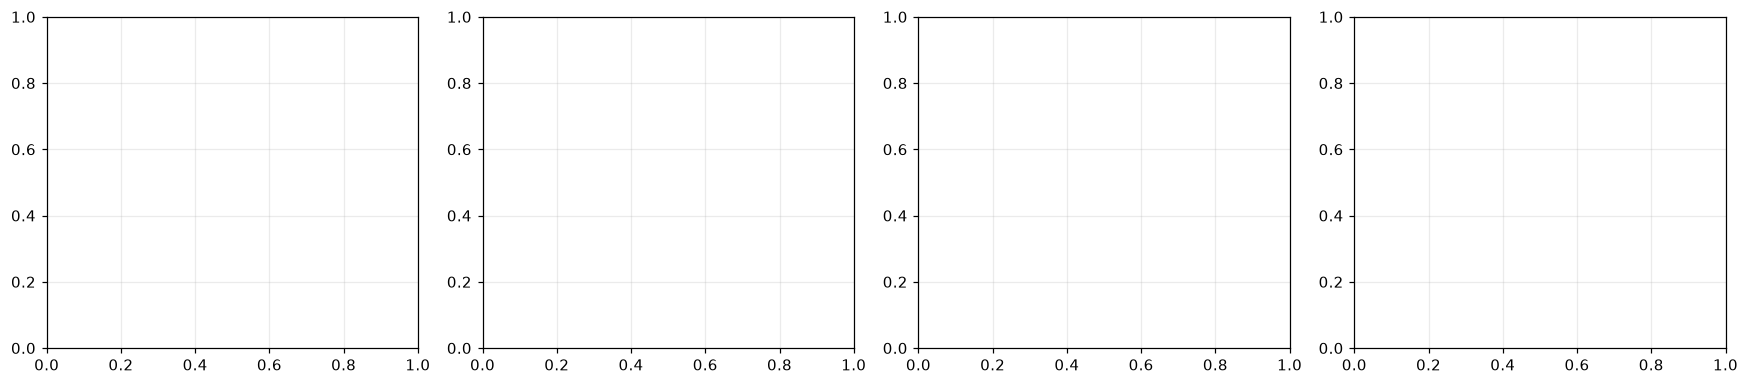

In [58]:
def plot_sixs():
    wlE = L1['ES']['wl']; fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
    im = ax[0].pcolormesh(wlE, np.arange(len(DIRECT)), DIRECT, shading='auto', cmap='viridis', vmin=0, vmax=1); plt.colorbar(im, ax=ax[0]); ax[0].set(title='direct ratio r(λ), record by record', xlabel='wavelength [nm]', ylabel='record')
    m, sd = DIRECT.mean(0), DIRECT.std(0); ax[1].plot(wlE, m); ax[1].fill_between(wlE, m - sd, m + sd, alpha=0.3); ax[1].set(title='mean ± sd of r(λ) over the file', xlabel='wavelength [nm]')
    for w, col in zip([450, 550, 700, 850], ['tab:blue', 'tab:green', 'tab:red', 'tab:brown']):
        j = np.argmin(np.abs(wlE - w)); ax[2].scatter(SZA_REC, DIRECT[:, j], s=8, color=col, label=f'{wlE[j]:.0f} nm')
    ax[2].set(title='r vs solar zenith angle', xlabel='SZA [deg]'); ax[2].legend(fontsize=6)
    ax[3].plot(SZA_REC, color='k'); ax[3].set(title='SZA through the file', xlabel='record', ylabel='deg'); plt.show()
if HAVE_L1: plot_sixs()

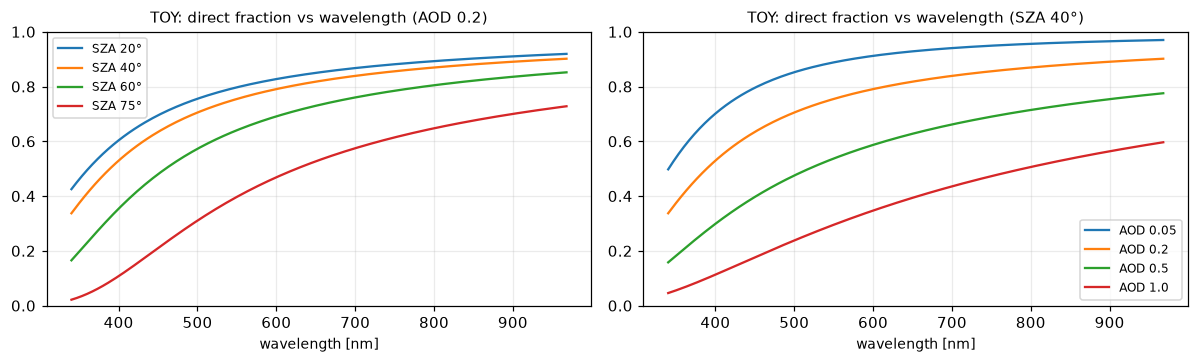

In [59]:
# What controls the direct fraction? (toy model — qualitative trends only; real values come from 6S)
if HAVE_L1:
    wlE = L1['ES']['wl']; fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    for z in [20, 40, 60, 75]: ax[0].plot(wlE, toy_direct(wlE, z, 0.2), label=f'SZA {z}°')
    ax[0].set(title='TOY: direct fraction vs wavelength (AOD 0.2)', xlabel='wavelength [nm]', ylim=(0, 1)); ax[0].legend()
    for a_ in [0.05, 0.2, 0.5, 1.0]: ax[1].plot(wlE, toy_direct(wlE, 40, a_), label=f'AOD {a_}')
    ax[1].set(title='TOY: direct fraction vs wavelength (SZA 40°)', xlabel='wavelength [nm]', ylim=(0, 1)); ax[1].legend(); plt.show()

In [60]:
RUN_LIVE_6S = False     # set True to run real 6S for ONE record (needs the j6s package and its 6S executable; ~190 runs)
if RUN_LIVE_6S and HAVE_L1:
    try:
        from j6s import SixS
        s6 = SixS(); i = REC; t = L1['ES']['time'][i]; aod = float(first_field(ANC.getDataset('AOD'))[0]) if (ANC is not None and 'AOD' in ANC.datasets) else float(S.get('fL1bDefaultAOD', 0.2))
        s6.geometry(sun_zen=SZA_REC[i], sun_azi=SAA_REC[i], view_zen=180, view_azi=REL_REC[i], month=t.month, day=t.day)
        s6.gas(); s6.aerosol(aot_550=aod); s6.target_altitude(); s6.sensor_altitude(); s6.to_be_implemented()
        wsub = L1['ES']['wl'][::8]; live = []
        for w in wsub:
            s6.wavelength(float(w)); out = s6.run(); live.append(float(out['percent_of_direct_solar_irradiance_at_target']))
        plt.figure(figsize=(6, 3)); plt.plot(L1['ES']['wl'], DIRECT[i], label=DIRECT_SOURCE[:30]); plt.plot(wsub, live, 'o', label='live 6S'); plt.legend(); plt.title(f'record #{i}: direct ratio'); plt.show()
    except Exception as err:
        print('live 6S failed:', repr(err))

## 7. The Full-FRM chain, step by step

Putting everything together, for each record $n$ and pixel $i$ of a channel the FRM calibration computes

$$
\boxed{\;
E_{n,i}= \underbrace{\frac{t_{cal}+\Delta T}{t_n+\Delta T}}_{\text{4 time}}\;
\underbrace{\frac{1}{g_i}}_{\text{5 gain}}\;
\Big[\;\underbrace{\mathbf{C}}_{\text{3 straylight}}\;
\underbrace{\big(x_i - \alpha_i\,x_i^{2}\big)}_{\text{2 non-linearity}},\;\; x_i=\underbrace{V_{n,i}-DC_n}_{\text{1 dark}}\Big]\;
\underbrace{\big(1+c_{T,i}\,(T_n-T_{cal})\big)}_{\text{6 thermal}}\;
\underbrace{\Big[r_{n,i}\,(1-\tfrac{\epsilon_{dir}}{100})+(1-r_{n,i})(1-\tfrac{\epsilon_{hemi}}{100})\Big]}_{\text{7 cosine (Ed only)}}\;}
$$

**Why this order?** The corrections undo the instrument in *reverse physical order*: the light is first spread by stray light inside the spectrometer, *then* the detector responds non-linearly, *then* the ADC counts it. Hence the **non-linearity is undone first and the straylight matrix second** — the two do not commute because the matrix mixes pixels with different signal levels. After those two *linear-in-counts* operations, the remaining factors (integration time, gain, thermal, cosine) are **per-pixel multiplicative scalars** and commute with each other.

**Differences from the factory path:** (i) non-linearity is *measured per pixel* instead of one global straight line; (ii) straylight is corrected (the factory path does nothing); (iii) the temperature coefficient comes from a dedicated characterisation and is applied relative to the *characterisation's* $T_{cal}$; (iv) the Ed cosine error is corrected using 6S; (v) the gain is derived **in HyperCP from the raw lamp data** (including straylight correction of the lamp signal) rather than taken from a pre-computed coefficient.

In [ ]:
def frm_chain(s, idx=None, direct=None, sza=None):
    """Apply the Full-FRM chain to a channel. idx = record indices (None = all). Returns every intermediate stage as (records × pixels)."""
    c, d = CHAR[s], L1[s]; sl = slice(None) if idx is None else np.atleast_1d(idx)
    raw, dc, t, T = d['raw'][sl], d['dc'][sl], d['t'][sl], d['T'][sl]
    st = {'0 raw V': raw}
    x = raw - dc[:, None];                                   st['1 dark'] = x
    x = x * (1 - c['alpha'][None, :] * x);                   st['2 non-linearity'] = x
    x = x @ c['C'].T;                                        st['3 straylight'] = x
    x = x * (c['tce'] / (t + c['dT']))[:, None];             st['4 integration time'] = x
    x = x / np.where(c['ok'], c['gain'], np.nan)[None, :];   st['5 gain'] = x
    x = x * (1 + c['cT'][None, :] * (T - c['T_cal'])[:, None]); st['6 thermal'] = x
    if s == 'ES':
        sym, fh = cosine_products(c, c['wl']); iz = np.argmin(np.abs(c['zen'][None, :] - sza[sl][:, None]), axis=1); r = direct[sl]
        x = x * (r * (1 - sym[:, iz].T / 100.) + (1 - r) * (1 - fh[None, :] / 100.)); st['7 cosine'] = x
    st['FRM'] = x
    return st

if HAVE_CHAR and HAVE_L1:
    FRM = {s: frm_chain(s, None, DIRECT, SZA_REC)['FRM'] for s in L1}
    print('FRM spectra computed for all records:', {s: FRM[s].shape for s in FRM})

In [ ]:
def plot_steps(rec):
    fig, ax = plt.subplots(2, 3, figsize=(16, 7.2))
    for k, s in enumerate(['ES', 'LI', 'LT']):
        st = frm_chain(s, rec, DIRECT, SZA_REC); wl = CHAR[s]['wl']; ok = CHAR[s]['ok']
        eff = {'2 non-linearity': st['2 non-linearity'] / st['1 dark'], '3 straylight': st['3 straylight'] / st['2 non-linearity'],
               '6 thermal': st['6 thermal'] / st['5 gain']}
        if '7 cosine' in st: eff['7 cosine'] = st['7 cosine'] / st['6 thermal']
        for name, r in eff.items():
            ax[0, k].plot(wl[ok], (r[0][ok] - 1) * 100, label=name)
        fac = FAC[s][rec]; ax[0, k].plot(wl[ok], (st['FRM'][0][ok] / fac[ok] - 1) * 100, 'k--', lw=1.5, label='TOTAL FRM vs factory')
        ax[0, k].set(title=f'{NAMES[s]}  record #{rec}: effect of each step [%]', xlabel='wavelength [nm]'); ax[0, k].legend(fontsize=6)
        ax[1, k].plot(wl[ok], st['FRM'][0][ok], label='FRM'); ax[1, k].plot(wl[ok], fac[ok], '--', label='factory')
        ax[1, k].set(title='calibrated spectrum [µW cm⁻² nm⁻¹' + ('' if s == 'ES' else ' sr⁻¹') + ']', xlabel='wavelength [nm]'); ax[1, k].legend()
    plt.show()
if HAVE_CHAR and HAVE_L1: plot_steps(REC)

In [ ]:
# How big is each step, in numbers? Median |effect| over 450–700 nm and 350–450 nm for this record.
def step_table(rec):
    rows = []
    for s in ['ES', 'LI', 'LT']:
        st = frm_chain(s, rec, DIRECT, SZA_REC); wl, ok = CHAR[s]['wl'], CHAR[s]['ok']
        pairs = [('2 non-linearity', '1 dark'), ('3 straylight', '2 non-linearity'), ('6 thermal', '5 gain')] + ([('7 cosine', '6 thermal')] if s == 'ES' else [])
        for a, b in pairs:
            r = (st[a][0] / st[b][0] - 1) * 100
            rows.append(dict(sensor=s, step=a, **{'350–450 nm [%]': np.nanmedian(r[ok & (wl > 350) & (wl < 450)]), '450–700 nm [%]': np.nanmedian(r[ok & (wl >= 450) & (wl <= 700)]), '700–900 nm [%]': np.nanmedian(r[ok & (wl > 700) & (wl <= 900)])}))
    return pd.DataFrame(rows).set_index(['sensor', 'step']).round(3)
if HAVE_CHAR and HAVE_L1: display(step_table(REC))

In [ ]:
# The non-linearity step depends on the SIGNAL LEVEL: its size is α·x, and x is set by the auto-exposure.
def plot_nl_vs_signal():
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
    for a, s in zip(ax, ['ES', 'LI', 'LT']):
        x = L1[s]['raw'] - L1[s]['dc'][:, None]; eff = (-CHAR[s]['alpha'][None, :] * x) * 100; ok = CHAR[s]['ok']
        a.scatter(x[:, ok].ravel(), eff[:, ok].ravel(), s=2, alpha=0.3, color=COL[s]); a.set(title=f'{NAMES[s]}: non-linearity correction vs signal', xlabel='V − DC [counts]', ylabel='−α·x  [%]')
    plt.show()
if HAVE_CHAR and HAVE_L1: plot_nl_vs_signal()

## 8. FRM versus factory over the whole file

If the two calibrations were identical the ratio would be 1 everywhere. Differences have different origins and **different time behaviour**, which is a good way to recognise them: stray light and angular response depend on spectral shape and sun geometry; thermal depends on temperature; gain differences are constant in time.

In [ ]:
def plot_frm_vs_factory():
    fig, ax = plt.subplots(2, 3, figsize=(16, 7))
    for k, s in enumerate(['ES', 'LI', 'LT']):
        wl, ok = CHAR[s]['wl'], CHAR[s]['ok']; ratio = FRM[s] / FAC[s]
        q10, q50, q90 = np.nanpercentile(ratio, [10, 50, 90], axis=0)
        ax[0, k].plot(wl[ok], q50[ok], color=COL[s]); ax[0, k].fill_between(wl[ok], q10[ok], q90[ok], color=COL[s], alpha=0.25)
        ax[0, k].axhline(1, color='k', lw=0.7); ax[0, k].set(title=f'{NAMES[s]}: FRM / factory (median, 10–90 %)', xlabel='wavelength [nm]')
        for w, col in zip([450, 550, 670, 800], ['tab:blue', 'tab:green', 'tab:red', 'tab:brown']):
            j = np.argmin(np.abs(wl - w)); ax[1, k].plot(L1[s]['time'], ratio[:, j], color=col, label=f'{wl[j]:.0f} nm')
        ax[1, k].set(title='FRM / factory through time'); ax[1, k].tick_params(axis='x', labelrotation=45); ax[1, k].legend(fontsize=6)
    plt.show()
if HAVE_CHAR and HAVE_L1: plot_frm_vs_factory()

In [ ]:
def plot_final_spectra():
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
    for a, s in zip(ax, ['ES', 'LI', 'LT']):
        ok = CHAR[s]['ok']; cm = plt.cm.viridis(np.linspace(0, 1, FRM[s].shape[0]))
        for i in range(0, FRM[s].shape[0], max(1, FRM[s].shape[0] // 30)): a.plot(CHAR[s]['wl'][ok], FRM[s][i][ok], color=cm[i], lw=0.8)
        a.set(title=f'{NAMES[s]}: FRM-calibrated spectra (colour = time)', xlabel='wavelength [nm]')
    plt.show()
if HAVE_CHAR and HAVE_L1: plot_final_spectra()

## 9. Cross-check against HyperCP's own implementation

If you have applied the DALEC FRM patch, `ProcessL1bDALEC.read_unc_coefficient_frm` and `ProcessL1bDALEC.processL1b_FRM` do all of §5–§7 on an HDF "node". The cell below builds such a node from the L1AQC file you loaded, feeds it the *same* direct ratio, and compares the result with this notebook, pixel by pixel. Agreement to ~1e-6 means that the notebook and the pipeline implement the same measurement equation.

In [ ]:
def crosscheck():
    from Source.ProcessL1bDALEC import ProcessL1bDALEC
    if not hasattr(ProcessL1bDALEC, 'processL1b_FRM'):
        print('ProcessL1bDALEC.processL1b_FRM not found — the FRM patch is not applied in this repository.'); return
    ProcessL1bDALEC.FRM_USE_INTTIME_OFFSET = USE_DT; ProcessL1bDALEC.FRM_ZONG_N_IB = N_IB
    node = copy.deepcopy(ROOT)
    for s in ['ES', 'LI', 'LT']:
        g = node.getGroup(s); g.addDataset('DATETIME').data = [pd.Timestamp(t).to_pydatetime() for t in L1[s]['time']]
        node.addGroup(f'{s}_L1AQC').copy(g)
    sg = node.addGroup('SIXS_MODEL'); dtp = np.dtype({'names': [str(x) for x in L1['ES']['wl']], 'formats': [np.float64] * len(L1['ES']['wl'])})
    for nm, arr in [('direct_ratio', DIRECT), ('diffuse_ratio', 1 - DIRECT), ('sixS_irradiance', 100 * DIRECT)]:
        sg.addDataset(nm).data = np.rec.fromarrays(arr.T, dtype=dtp)
    sg.addDataset('solar_zenith').data = np.array(SZA_REC.tolist(), dtype=[('solar_zenith', '<f8')])
    if ProcessL1bDALEC.read_unc_coefficient_frm(node) is None or not ProcessL1bDALEC.processL1b_FRM(node):
        print('the pipeline function reported an error (see messages above)'); return
    rows = []
    for s in ['ES', 'LI', 'LT']:
        out = np.asarray(pd.DataFrame(node.getGroup(s).getDataset(s).data), float); ok = CHAR[s]['ok']
        rows.append(dict(sensor=s, pixels_pipeline=out.shape[1], pixels_notebook=int(ok.sum()), max_rel_diff=float(np.nanmax(np.abs(out / FRM[s][:, ok] - 1))) if out.shape[1] == ok.sum() else np.nan))
    display(pd.DataFrame(rows).set_index('sensor'))
if HAVE_CHAR and HAVE_L1: crosscheck()

## 10. Glossary and things to verify

| term | meaning |
|---|---|
| **FRM** | *Fiducial Reference Measurements*: measurements with a fully characterised instrument and traceable uncertainty (FRM4SOC project) |
| **FidRadDB** | database/format of the laboratory characterisation files |
| **LSF / SDF** | line-spread function / scattering distribution function (straylight) |
| **A, C** | straylight forward matrix and its inverse (correction) |
| **α** | non-linearity coefficient, in count⁻¹; corrected value = x·(1 − αx) |
| **c<sub>T</sub>** | per-pixel thermal coefficient; corrected value = x·(1 + c<sub>T</sub>·ΔT) |
| **ε(θ,λ)** | cosine error of the Ed collector [%] |
| **r(λ)** | direct fraction of downwelling irradiance (from 6S) |
| **ΔT (Delta_T)** | integration-time offset of the DALEC: effective exposure = INTTIME + ΔT |
| **t<sub>cal</sub>, t1, t2** | integration times in the RADCAL settings row |

**Assumptions worth verifying against your real files** (all visible in the plots above):

1. **RADCAL layout** — row 0 holds `t_cal`, `t1`, `t2`; `raw1/raw2` are comparable signals (α panel: small, smooth, near the factory `d1/d0`). *(§5.1)*
2. **Gain agreement** — FRM gain vs factory-equivalent gain within a few % in the 450–700 nm range; large differences point to units or pixel-alignment problems. *(§5.1)*
3. **THERMAL sign** — correlation of `c_T` with the factory `Tempco` should be *negative* if `c_T` is a correction coefficient (HyperCP multiplies by `1 + c_T·ΔT`). *(§5.3)*
4. **Integration-time offset** — try `USE_DT = False` and see how much the FRM/factory ratio changes with integration time. *(§4, §8)*
5. **File selection** — if all characterisation files are *later* than your data, HyperCP takes the closest in time; check the "selection rule" column in §5. *(§5)*
6. **POLAR is not applied** (uncertainty only) — as for SeaBird and TriOS.

**Where to go next.** Change `L1AQC_FILE` (§1d) to look at another file, `REC` (§4) to look at another record, or `USE_DT` / `N_IB` (§5) to test the influence of those choices.